# Where the model picks its coding algorithm: plan subspace vs random pushes (Qwen3-8B, task T10)

Qwen3-8B (thinking off, T = 1) writes nearly the same algorithm every time for a given coding task: a full sort for "k-th smallest", Dijkstra for weighted shortest paths, **union-find** for "count the connected components of a graph" (task **T10**). Iteration 3 of this project found that **random pushes** to the residual stream at the task-specification positions sometimes make the model write a *different, correct* algorithm. This experiment asks **which** random pushes do that, and whether a **plan subspace** `P_t`, read from forward passes alone, explains it.

| Term | Meaning |
|---|---|
| S-mean state | mean residual-stream state over the task-spec positions `[Task: … spec_end)` after decoder block l |
| `c_X`, `cm_X` | centroid of the S-mean states of 30 forced prompts "Implement X for this task." (named), or of 30 name-free descriptions of X (masked) |
| plan subspace `P_t` | span of `{c_X − c_default : X ≠ default}` at block l, with orthonormal basis `Q_l` (rank k = #algorithms − 1) |
| push | an edit at blocks 12–23 during the prompt prefill: the displacement from the clean *twin* prompt along a random unit direction `u` is exactly α ban units |
| `π(u)` | projection share `mean_{l=12..23} ‖Q_lᵀu‖²`: the **primary predictor** (claim C2a), committed before any sample was drawn |
| `y(u)` | off-default share of the programs written under the push (first 10 slots, mean of α = 1 and 2) |

**Full-run headline** (6 movable tasks; 13,500 programs; 2.51 GPU-hours on an RTX 2000 Ada).

- The plan subspace is real and reliable: split-half principal cosine 0.89–0.97, vs 0.02 for random subspaces.
- **C2a is disconfirmed.** π(u) does not rank which of 40 fresh random directions move the algorithm (ρ < 0.2 on all 6 tasks; pooled within-task ρ = 0.03).
- The null is not noise: the ranking of directions is itself reproducible (template split-half ρ = 0.76–0.90).
- Exploratory: the **signed** progress of the push toward the runner-up algorithm's centroid tracks the effect (up to ρ = 0.57); the unsigned share does not.

**What runs here.** `method.py` orchestrates eight stages. The GPU stages (forward passes of 4,144 prompts; 13,500 sampled and labelled programs) cannot run in a notebook. Their outputs for task T10 come from `mini_demo_data.json`: one example per random direction from the artifact's `c2a_population` dataset, plus the forward-pass activations the predictors are built from. The CPU stages then run here with the original code:

1. **S3, plan subspace and predictors** (`src/subspace.py`): `P_t` from the activation centroids, π(u) and its secondaries for the 40 directions, and the split-half reliability.
2. **S7, escape rule and the C2a test** (`analysis/common.py`, `analysis/c2a.py`, `analysis/run_all.py`): Spearman ρ(π, y) with its permutation null and a Haar random-subspace null, plus every committed control.
3. **Exploratory** (`analysis/explore.py`): how reliable y is, and signed vs unsigned features of the realised push displacement at block 18.
4. **Geometry** (`analysis/geometry.py`): Isomap, MDS and persistent H1 of the forced-prompt states at block 18, with the twins, bans and pushed states projected in.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, ripser (+ its dependency persim) — NOT on Colab, always install (versions pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3', 'ripser==0.6.15')

# numpy, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- original imports (method.py, src/subspace.py, analysis/common.py, c2a.py, run_all.py, explore.py, geometry.py,
#     figures.py); figures.py also calls matplotlib.use("Agg"), left out so that the figures render inline
import json
import math
import os
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Iterable

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from scipy import stats
from scipy.sparse.csgraph import shortest_path
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, Isomap, trustworthiness
from sklearn.neighbors import kneighbors_graph

# --- added for the notebook: decoding the base64 arrays of mini_demo_data.json, a stdout log sink
#     (src_base/cfg.py setup_logging adds stdout + a rotating file; only stdout is kept here), silencing scipy's
#     sparse-efficiency notes that Isomap triggers when it joins the components of the kNN graph, and printing
#     warnings without the library's file path
import base64
import warnings
from scipy.sparse import SparseEfficiencyWarning

logger.remove()
logger.add(sys.stdout, format="{time:HH:mm:ss} | {level} | {message}")
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-4/experiment-22/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["about"])
print(f"\ntask {data['task']} ({data['task_name']}); default algorithm: {data['default']}; "
      f"catalogue: {data['catalogue']}")
print(f"{len(data['examples'])} direction examples, {sum(len(e['slots']) for e in data['examples'])} CRN slots, "
      f"{len(data['twin_rows'])} committed twin slots")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Task-T10 slice of the experiment-22 artifact 'Where the model picks its coding algorithm' (Qwen3-8B @ b968826d, FP8 W8A8, thinking off, T = 1). One example per fresh random push direction from the c2a_population dataset, plus the forward-pass activations that the plan subspace and its predictors are built from. Built by build_mini_demo_data.py.

task T10 (connected components of an undirected graph); default algorithm: union_find; catalogue: ['bfs', 'dfs', 'union_find', 'label_propagation']
40 direction examples, 1040 CRN slots, 50 committed twin slots


## Configuration

The tunable parameters come first. They are set to the full-run values, which their comments repeat. On a 2-CPU machine the whole analysis takes under a minute after the installs.

- `N_DIRECTIONS` keeps the first n of the 40 random directions.
- The other counts set the sizes of the permutation, null-model and split resamplings.
- `DO_PERSISTENCE` switches the ripser test off.

Lower values run faster but give noisier p-values. With the full values every T10 number of the original run is reproduced (section 9). The design constants below them are copied from `src/cfg4.py`, narrowed to the one task in this slice.

In [5]:
# ---------------------------------------------------------------- tunable parameters
# Each comment gives the full-run (original) value.
N_DIRECTIONS = 40          # fresh random push directions analysed, the first n of seeds 9101-9140 (original: 40)
N_PERM = 10000             # shuffles of y per Spearman permutation test (original: 10,000)
N_HAAR = 1000              # Haar random k-dim subspaces per block, random-subspace null of rho_pi (original: 1,000)
N_SPLIT_AUC = 200          # random half/half splits, logistic-AUC sensitivity (original: 200)
N_SPLIT_HALF = 200         # split-half draws, subspace reliability (original: 200)
N_PERM_EXPLORE = 2000      # shuffles per feature, exploratory block profile (original: 2,000)
N_PERM_RELIABILITY = 5000  # shuffles, reliability of y (original: 5,000)
N_NULL = 200               # coordinate-permutation draws for persistent H1 (original: 200)
DO_PERSISTENCE = True      # run the ripser persistence test (original: True)
KNN_KS = (5, 10, 15)       # kNN graph sizes for Isomap / MDS; keep 10, it gives the embedding (original: 5, 10, 15)

# ---------------------------------------------------------------- design constants (src/cfg4.py, src_base/cfg.py)
TASK = data["task"]                       # this slice: T10 (connected components; default union-find)
MOVABLE = (TASK,)                         # original: ("T03", "T2", "T05", "T10", "T06", "T1")
TASKS15 = MOVABLE                         # original: MOVABLE + the 9 other tasks
DEFAULT4 = {TASK: data["default"]}
D_MODEL = 4096
TEMPLATE_IDS = ["W1", "W2", "W3", "W4", "W5"]
EDIT_BLOCKS = list(range(12, 24))
CAP_BLOCKS = list(range(12, 36))
LATE_BLOCKS = list(range(24, 36))
GEO_BLOCKS = (data["activations"]["state_block"],)   # original: (18, 23); the slice carries block 18
SEEDS_POP = list(range(9101, 9141))[:N_DIRECTIONS]
SEEDS_OTHER = list(range(9101, 9109))
ALPHAS_POP = (1.0, 2.0)
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.8
K = {"twin_mov": list(range(10)), "twin_oth": list(range(6)), "pop": [0, 1], "topup": [2, 3, 4, 5],
     "decomp": [0, 1, 2, 3], "k30": list(range(6)), "k50": list(range(10))}
print(f"{TASK}: {len(SEEDS_POP)} directions, alphas {ALPHAS_POP}, edit blocks {EDIT_BLOCKS[0]}-{EDIT_BLOCKS[-1]}, "
      f"geometry block(s) {GEO_BLOCKS}")

T10: 40 directions, alphas (1.0, 2.0), edit blocks 12-23, geometry block(s) (18,)


## 1. The pipeline: `method.py`

`method.py` is the artifact's entry point. It runs each stage's scripts as subprocesses. Its code is shown unchanged below, except that `main()` takes the argument list instead of reading `sys.argv`, and the module docstring is kept as `METHOD_DOC`. Called with no stage, as here, it only prints the stage map.

| Stage | Hardware | In this notebook |
|---|---|---|
| `s0`, `prompts` | CPU and OpenRouter (USD 0.03) | outputs loaded: prompt texts, the iteration-3 screen landing |
| `gpu1` | GPU, about 32 min | outputs loaded: S-mean states at block 18, centroids at blocks 12–23, realised push displacements at block 18 |
| `commit` (S3 + S4) | CPU | **runs** (section 3): `P_t`, π(u) and the secondary predictors |
| `label`, `gpu2` | GPU, 2.5 h, plus the labeller | outputs loaded: the labelled programs of every push and of the twin |
| `analyze` (S7) | CPU | **runs** (sections 4–8): escape, C2a, exploratory, geometry |
| `outputs` (S8) | CPU | replaced by the summary in section 9 |

In [6]:
METHOD_DOC = """Where the model's algorithm choice lives -- orchestrator (Qwen3-8B, FP8 W8A8 on a 16 GB RTX 2000 Ada).

Stages (each resumable; see README.md):
  s0        input copies + sha256 + bench verification, screen file (entry #0), labeller re-check
  prompts   masked descriptions (OpenRouter, leak-checked) + all 4,144 prompts
  gpu1      GPU unit tests, engine check (screen replication), states, units, realised displacements
  commit    S3 plan subspace + predictors, then S4 commit (predictions/c2_commit.json, commitments.log)
  label     label worker (run concurrently with gpu2)
  gpu2      S5 sampling stages A-H
  analyze   S7 analyses + figures (analysis/run_all.py)
  outputs   S8 method_out.json (+ mini/preview), audit
"""

ROOT = Path.cwd()   # original: Path(__file__).resolve().parent, the artifact folder that holds src/ and analysis/
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(k, "4")   # the cgroup allows ~5 CPUs; unbounded BLAS threads oversubscribe them
PY = sys.executable


def sh(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run([PY, *args], cwd=ROOT, check=True)


def main(argv: list[str]) -> None:   # original: main(), reading sys.argv
    stage = argv[1] if len(argv) > 1 else "help"
    extra = argv[2:]
    if stage == "s0":
        sh("src/s0_setup.py")
        sh("src/screen.py")
        sh("src/recheck4.py")
    elif stage == "prompts":
        sh("src/describe.py")
        sh("src/prompts4.py")
    elif stage == "gpu1":
        sh("src/gpu_phase1.py", *(extra or ["tests", "engine", "states", "units", "realised"]))
    elif stage == "commit":
        sh("analysis/tests_cpu.py")
        sh("src/subspace.py")
        sh("src/make_commit.py")
    elif stage == "label":
        sh("src/label4.py", *extra)
    elif stage == "gpu2":
        sh("src/gpu_phase2.py", *extra)
    elif stage == "analyze":
        sh("analysis/run_all.py", *extra)
    elif stage == "outputs":
        sh("analysis/outputs.py", *extra)
        sh("audit/rederive.py")
    else:
        print(METHOD_DOC)   # original: print(__doc__)


main(["method.py"])   # = `python method.py` with no stage: prints the stage map (the stages need the full repository)

Where the model's algorithm choice lives -- orchestrator (Qwen3-8B, FP8 W8A8 on a 16 GB RTX 2000 Ada).

Stages (each resumable; see README.md):
  s0        input copies + sha256 + bench verification, screen file (entry #0), labeller re-check
  prompts   masked descriptions (OpenRouter, leak-checked) + all 4,144 prompts
  gpu1      GPU unit tests, engine check (screen replication), states, units, realised displacements
  commit    S3 plan subspace + predictors, then S4 commit (predictions/c2_commit.json, commitments.log)
  label     label worker (run concurrently with gpu2)
  gpu2      S5 sampling stages A-H
  analyze   S7 analyses + figures (analysis/run_all.py)
  outputs   S8 method_out.json (+ mini/preview), audit



## 2. What the GPU stages produced for T10

**Prompts.** Every prompt is one first line followed by the same task specification.

- The **twin** is the neutral control: a ban of a nonsense word ("Do not use ship for this task."), padded to the ban's token length, in 5 templates W1–W5.
- The **ban** names the default ("Do not use union-find (disjoint set union) for this task.").
- The **named** forced prompts say "Implement X for this task." (10 templates × 3 names = 30 per algorithm).
- The **masked** forced prompts describe the mechanism without naming it (30 leak-checked LLM descriptions per algorithm).

**States (`gpu1`).** One FP8 prefill per prompt. The S-mean state at block l is the mean residual-stream state after decoder block l over the positions `S = [first token of "Task:", spec_end)`. The slice carries the per-prompt states at block 18 and the per-algorithm centroids at blocks 12–23. The centroids are the exact float32 means of the float16 states; section 3 checks this on block 18.

**Pushes (`gpu2`).** A push edits the twin's prefill at blocks 12–23 on the positions S (TARGET edit, `src/hooks4.py`):

```
h_S <- h_S + (M_l - (h_S - h_twin) . U_l) U_l      with U_l = u (a random unit direction), M_l[p] = alpha * n_l[p]
```

So the displacement from the clean twin along `u` is exactly α ban units at every position. The ban unit `n_l[p]` is the per-position norm of the iteration-3 ban's own displacement.

Common random numbers (CRN) couple every arm to the twin: a slot (template, k) uses the same sampling uniforms in every arm. Each program was labelled by a runtime tracer plus the AST, with a blind LLM judge only on disagreement, and run against hidden tests.

**Realised displacement.** `δ_l = mean_{p∈S}(h_arm − h_twin)` of every population push was logged during its prefill. The slice carries it at block 18: 400 vectors = 40 directions × 2 α × 5 templates.

In [7]:
def decode(rec: dict[str, Any]) -> np.ndarray:
    """An array record of mini_demo_data.json -> numpy array (replaces npz_parts.load of the states/ files)."""
    return np.frombuffer(base64.b64decode(rec["b64"]), dtype=rec["dtype"]).reshape(rec["shape"])


A = data["activations"]
modes = A["modes"]                        # algorithm names, sorted (as in states/subspace_<task>.npz)
c_named = decode(A["c_named"])            # [M, 12, D] float32: centroid of the 30 named states, blocks 12-23
c_masked = decode(A["c_masked"])          # [M, 12, D] float32: centroid of the 30 masked states, blocks 12-23
meta = A["states_meta"]                   # one record per prompt: kind (named / masked / twin / ban), X, template_id
H18 = decode(A["states_smean"]).astype(np.float32)[:, None, :]   # [n, 1, D]: S-mean states at block 18
pop_keys = A["pop_delta_keys"]            # 'POP|seed|alpha|template' of the 400 population pushes
D18 = decode(A["pop_delta_smean"])        # [400, D] float16: realised S-mean displacement of each push, block 18
screen = {"tasks": {TASK: data["screen"]}}   # results/screen.json: the iteration-3 screen landing of this task


def catalogue(task: str) -> list[str]:
    return list(data["catalogue"])        # original (src/screen.py): the catalogue of the bench task's spec.json


print("twin prompt (template W1):\n  " + data["prompts"]["W1"].replace("\n", "\n  "))
print("\nfirst lines of the other prompt kinds (the task specification that follows is the same):")
for kind, seg in data["forced_prompt_examples"].items():
    print(f"  {kind:7s} {seg}")
print(f"\nalgorithms {modes}; prompts per kind {dict(Counter(m['kind'] for m in meta))}")
print(f"c_named {c_named.shape} {c_named.dtype} | H18 {H18.shape} | D18 {D18.shape} {D18.dtype}")

twin prompt (template W1):
  Do not use ship for this task. . . . . . . .
  
  Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to n - 1, with 1 <= n <= 300. The argument edges is a list of pairs [u, v] with 0 <= u, v < n and u != v, each joining nodes u and v; 0 <= len(edges) <= 1500 and no pair of nodes is joined twice. A node with no edges forms a component on its own.
  
  Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

first lines of the other prompt kinds (the task specification that follows is the same):
  named   Implement depth-first search (DFS) for this task.
  masked  Implement the approach described as: Iterate over each node, and when an unvisited node is found, use a last-in-first-out stack to traverse all reachable nodes, marking them as visited, then increme

## 3. S3: the plan subspace `P_t` and the committed predictors (`src/subspace.py`)

The functions below are copied from `src/subspace.py`, and `rand_dir` from `src/ctx4.py`. Per task and block l:

- `c_X` is the mean of the 30 named S-mean states of algorithm X; `cm_X` is the masked analogue.
- `Q_l` is an orthonormal basis (SVD) of `{c_X − c_def : X ≠ def}`, with rank k = M − 1.
- `a_l` = unit(mean_{X≠def} c_X − c_def) is the mean non-default axis.
- `r_l` = unit(c_ru − c_def) is the runner-up axis. The runner-up `ru` is the iteration-3 screen's push landing (DFS for T10).

The 40 random directions are regenerated exactly from their seeds: `PCG64(seed).standard_normal(4096)`, normalised.

In [8]:
# ---------------------------------------------------------------- src/ctx4.py
DIR_DIR = Path("directions")      # original: <artifact>/directions, a cache of rand_<seed>.npy
E17 = Path("inputs") / "exp17"    # original: the iteration-3 exp17 inputs; absent here, so directions are regenerated
DIR_DIR.mkdir(exist_ok=True)


def rand_dir(seed: int) -> np.ndarray:
    """exp17 _RandDirs construction: PCG64(seed).standard_normal(4096), normalised; saved on first use."""
    p = DIR_DIR / f"rand_{seed}.npy"
    if p.exists():
        return np.load(p)
    src = E17 / "directions" / f"rand_{seed}.npy"
    if src.exists():
        v = np.load(src)
    else:
        x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
        v = (x / np.linalg.norm(x)).astype(np.float32)
    np.save(p, v)
    return v


# ---------------------------------------------------------------- src/subspace.py
BI = {l: i for i, l in enumerate(CAP_BLOCKS)}
EI = [BI[l] for l in EDIT_BLOCKS]
LI = [BI[l] for l in LATE_BLOCKS]


def unit(x: np.ndarray) -> np.ndarray:
    return x / max(float(np.linalg.norm(x)), 1e-12)


def orth(V: np.ndarray, k: int | None = None) -> np.ndarray:
    """Orthonormal basis of the column span of V [D, m] via SVD (rank k = m by default)."""
    U, S, _ = np.linalg.svd(V, full_matrices=False)
    k = k or V.shape[1]
    return U[:, :k]


def class_index(meta: list[dict[str, Any]], kind: str) -> dict[str, np.ndarray]:
    out: dict[str, list[int]] = {}
    for i, m in enumerate(meta):
        if m["kind"] == kind:
            out.setdefault(m["X"], []).append(i)
    return {k: np.array(v) for k, v in out.items()}


def centroids(H: np.ndarray, idx: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    return {X: H[ii].mean(0) for X, ii in idx.items()}   # [24, D] per X


def plan_basis(C: dict[str, np.ndarray], default: str, bi: int, modes: list[str] | None = None) -> np.ndarray:
    others = [X for X in (modes or C) if X != default and X in C]
    V = np.stack([C[X][bi] - C[default][bi] for X in others], 1).astype(np.float64)
    return orth(V, len(others))


def proj_share(Q: np.ndarray, v: np.ndarray) -> float:
    v = v.astype(np.float64)
    nv = float(v @ v)
    return float(np.sum((Q.T @ v) ** 2) / max(nv, 1e-30))


def runner_ups(task: str, C: dict[str, np.ndarray], screen: dict[str, Any]) -> tuple[str, str, dict[str, Any]]:
    d = DEFAULT4[task]
    st = screen["tasks"][task]
    dist18 = {X: float(np.linalg.norm(C[X][BI[18]] - C[d][BI[18]])) for X in C if X != d}
    near = sorted(dist18, key=dist18.get)
    ru = st.get("runner_up_screen") or near[0]
    src_ru = "screen push-landing top-1" if st.get("runner_up_screen") else "nearest named centroid at block 18"
    if st.get("second_screen"):
        r2, src2 = st["second_screen"], "screen second landing"
    else:
        cand = [X for X in near if X != ru]
        r2, src2 = cand[0], "nearest other named centroid at block 18"
    return ru, r2, {"runner_up": ru, "runner_up_source": src_ru, "second": r2, "second_source": src2,
                    "dist18": dist18}


def split_half(H: np.ndarray, idx: dict[str, np.ndarray], default: str, bi: int, n_split: int = N_SPLIT_HALF,
               seed: int = 0) -> dict[str, Any]:   # original default n_split: 200
    rng = np.random.default_rng(seed)
    cos: dict[str, list[float]] = {X: [] for X in idx if X != default}
    pa: list[float] = []
    for _ in range(n_split):
        A, Bc = {}, {}
        for X, ii in idx.items():
            p = rng.permutation(ii)
            h = len(p) // 2
            A[X] = H[p[:h], bi].mean(0)
            Bc[X] = H[p[h:2 * h], bi].mean(0)
        others = [X for X in idx if X != default]
        for X in others:
            da, db = A[X] - A[default], Bc[X] - Bc[default]
            cos[X].append(float(da @ db / max(np.linalg.norm(da) * np.linalg.norm(db), 1e-12)))
        QA = orth(np.stack([A[X] - A[default] for X in others], 1).astype(np.float64))
        QB = orth(np.stack([Bc[X] - Bc[default] for X in others], 1).astype(np.float64))
        sv = np.linalg.svd(QA.T @ QB, compute_uv=False)
        pa.append(float(np.mean(sv)))
    k = len(idx) - 1
    rng2 = np.random.default_rng(seed + 1)
    rand = []
    for _ in range(50):
        QA = np.linalg.qr(rng2.standard_normal((H.shape[-1], k)))[0]
        QB = np.linalg.qr(rng2.standard_normal((H.shape[-1], k)))[0]
        rand.append(float(np.mean(np.linalg.svd(QA.T @ QB, compute_uv=False))))
    return {"cos_diff_mean": {X: float(np.mean(v)) for X, v in cos.items()},
            "cos_diff_q05": {X: float(np.quantile(v, 0.05)) for X, v in cos.items()},
            "principal_cos_mean": float(np.mean(pa)), "principal_cos_q05": float(np.quantile(pa, 0.05)),
            "random_subspace_principal_cos_mean": float(np.mean(rand))}


def snr(H: np.ndarray, idx: dict[str, np.ndarray], C: dict[str, np.ndarray], default: str, bi: int) -> dict[str, Any]:
    res = []
    for X, ii in idx.items():
        res.append(H[ii, bi] - C[X][bi])
    Rm = np.concatenate(res, 0)
    tr = float(np.sum(Rm ** 2) / max(Rm.shape[0] - len(idx), 1))   # tr(Sigma_within), pooled
    n_per = np.mean([len(ii) for ii in idx.values()])
    return {X: float(np.sum((C[X][bi] - C[default][bi]) ** 2) / (2 * tr / n_per)) for X in idx if X != default}

### 3a. Pass 1: centroids, `P_t`, axes and reliability

The original pass runs for 15 tasks at 24 blocks from `states/states_<task>.npz`. Here it runs for T10 from the slice, with the same lines. The centroids at blocks 12–23 build `Q_l`, `a_l` and `r_l`. The per-prompt states at block 18 give:

- the **split-half reliability**: do two random 15/15 halves of the paraphrases span the same subspace?
- the **separation SNR** of each algorithm from the default;
- the **share of the iteration-3 ban's own displacement** (ban prompt − twin prompt) that lies in `P_t`. The original averages this over blocks 12–23; here it is block 18 only.

In [9]:
t = TASK
d = DEFAULT4[t]
nidx, midx = class_index(meta, "named"), class_index(meta, "masked")
assert d in nidx, f"{t}: default {d} missing from named prompts"
modes = sorted(nidx)
# the shipped centroids are exactly centroids() of the per-prompt states: checked on block 18, the block in the slice
C18 = centroids(H18, nidx)
assert all(np.array_equal(C18[X][0], c_named[j, BI[18]]) for j, X in enumerate(modes))
C = {X: c_named[j] for j, X in enumerate(modes)}     # [12, D] per X; original: C = centroids(H, nidx), 24 blocks
Cm = {X: c_masked[j] for j, X in enumerate(modes)}   # original: Cm = centroids(H, midx)
ru, r2, rinfo = runner_ups(t, C, screen)
k = len(modes) - 1
Q = np.stack([plan_basis(C, d, BI[l]) for l in EDIT_BLOCKS])          # [12, D, k]; original: over CAP_BLOCKS
Qm = np.stack([plan_basis(Cm, d, BI[l]) for l in EDIT_BLOCKS])
a_ax = np.stack([unit(np.mean([C[X][BI[l]] for X in modes if X != d], 0) - C[d][BI[l]]) for l in EDIT_BLOCKS])
r_ax = np.stack([unit(C[ru][BI[l]] - C[d][BI[l]]) for l in EDIT_BLOCKS])
D_r = np.array([np.linalg.norm(C[ru][BI[l]] - C[d][BI[l]]) for l in EDIT_BLOCKS])
rel = {"block18": split_half(H18, nidx, d, 0),                 # original: split_half(H, nidx, d, BI[18])
       "block18_masked": split_half(H18, midx, d, 0, seed=7)}
dist_named_masked = {X: float(np.dot(unit(C[X][BI[18]] - C[d][BI[18]]), unit(Cm[X][BI[18]] - Cm[d][BI[18]])))
                     for X in modes if X != d}
snr18 = snr(H18, nidx, C18, d, 0)                              # original: snr(H, nidx, C, d, BI[18])
# the ban's own displacement projection share per template (original: mean over blocks 12-23; here block 18 only)
pi_ban18 = {}
for w in TEMPLATE_IDS:
    ib = [i for i, m in enumerate(meta) if m["kind"] == "ban" and m["template_id"] == w]
    it = [i for i, m in enumerate(meta) if m["kind"] == "twin" and m["template_id"] == w]
    if ib and it:
        dv = H18[ib[0]] - H18[it[0]]
        pi_ban18[w] = float(proj_share(Q[BI[18]], dv[0]))
logger.info(f"S3 {t}: k={k} ru={ru} r2={r2} rel18 pc={rel['block18']['principal_cos_mean']:.3f} "
            f"(rand {rel['block18']['random_subspace_principal_cos_mean']:.3f}) D_r18={D_r[BI[18]]:.1f}")

ct = data["committed_task"]
print(f"runner-up {ru} ({rinfo['runner_up_source']}), second {r2} ({rinfo['second_source']}); "
      f"committed: {ct['runner_up']['runner_up']}, {ct['runner_up']['second']}")
print("block-18 distance of each centroid from the default:", {X: round(v, 2) for X, v in rinfo["dist18"].items()})
print(f"split-half principal cosine at block 18: named {rel['block18']['principal_cos_mean']:.3f}, "
      f"masked {rel['block18_masked']['principal_cos_mean']:.3f}, random {k}-dim subspaces "
      f"{rel['block18']['random_subspace_principal_cos_mean']:.3f} (committed: "
      f"{ct['reliability']['block18']['principal_cos_mean']:.3f}, "
      f"{ct['reliability']['block18_masked']['principal_cos_mean']:.3f}, "
      f"{ct['reliability']['block18']['random_subspace_principal_cos_mean']:.3f})")
print("split-half cosine of each difference vector c_X - c_def:",
      {X: round(v, 3) for X, v in rel["block18"]["cos_diff_mean"].items()})
print("named vs masked difference-vector cosine:", {X: round(v, 3) for X, v in dist_named_masked.items()})
print("separation SNR at block 18:", {X: round(v, 1) for X, v in snr18.items()},
      "| committed:", {X: round(v, 1) for X, v in ct["snr_block18"].items()})
print(f"iteration-3 ban displacement: share in P_t at block 18 {np.mean(list(pi_ban18.values())):.3f} "
      f"(mean of W1-W5; committed mean over blocks 12-23: {np.mean(list(ct['pi_ban_per_template'].values())):.3f}) "
      f"vs k/4096 = {k / 4096:.5f} for an isotropic direction")

08:13:51 | INFO | S3 T10: k=3 ru=dfs r2=label_propagation rel18 pc=0.902 (rand 0.022) D_r18=4.3


runner-up dfs (screen push-landing top-1), second label_propagation (nearest other named centroid at block 18); committed: dfs, label_propagation
block-18 distance of each centroid from the default: {'bfs': 4.33, 'dfs': 4.31, 'label_propagation': 3.8}
split-half principal cosine at block 18: named 0.902, masked 0.902, random 3-dim subspaces 0.022 (committed: 0.902, 0.902, 0.022)
split-half cosine of each difference vector c_X - c_def: {'bfs': 0.971, 'dfs': 0.969, 'label_propagation': 0.947}
named vs masked difference-vector cosine: {'bfs': 0.654, 'dfs': 0.656, 'label_propagation': 0.539}
separation SNR at block 18: {'bfs': 52.8, 'dfs': 52.4, 'label_propagation': 40.6} | committed: {'bfs': 52.8, 'dfs': 52.4, 'label_propagation': 40.6}
iteration-3 ban displacement: share in P_t at block 18 0.195 (mean of W1-W5; committed mean over blocks 12-23: 0.255) vs k/4096 = 0.00073 for an isotropic direction


### 3b. Pass 2: predictors of the random directions

Four predictors are recomputed from the subspace just built:

- `π(u)`, the primary predictor;
- `π_masked(u)`;
- `s(u)` = mean_l ⟨u, a_l⟩;
- `s_runner_up(u)` = mean_l ⟨u, r_l⟩.

They are compared with the values committed in `predictions/c2_commit.json` (hash-chained before the first population sample). The other committed predictors need data outside this slice, so they are taken from the commit: other tasks' subspaces, within-class residuals at every block, and realised displacements at blocks 12–35. A random direction is expected to have π ≈ k/4096.

In [10]:
seeds = SEEDS_POP
pred = {}
for s in seeds:
    u = rand_dir(s).astype(np.float64)
    p = {"pi": float(np.mean([proj_share(Q[BI[l]], u) for l in EDIT_BLOCKS])),
         "pi_masked": float(np.mean([proj_share(Qm[BI[l]], u) for l in EDIT_BLOCKS])),
         "s": float(np.mean([u @ a_ax[BI[l]] for l in EDIT_BLOCKS])),
         "s_runner_up": float(np.mean([u @ r_ax[BI[l]] for l in EDIT_BLOCKS]))}
    pred[str(s)] = p
mean_pi = float(np.mean([pred[str(s)]["pi"] for s in seeds]))
logger.info(f"S3 predictors {t}: mean pi {mean_pi:.5f} (k/4096 = {k / 4096:.5f})")

# every predictor as committed in predictions/c2_commit.json; the four recomputed above replace their committed copy
committed = {str(e["direction_seed"]): e["committed_predictors"] for e in data["examples"]}
for nm in ("pi", "pi_masked", "s", "s_runner_up"):
    dev = max(abs(pred[str(s)][nm] - committed[str(s)][nm]) for s in seeds)
    big = max(abs(committed[str(s)][nm]) for s in seeds)
    print(f"{nm:12s} recomputed vs committed: max |difference| {dev:.1e} (largest |value| {big:.1e})")
preds = {str(s): {**committed[str(s)], **pred[str(s)]} for s in seeds}
commit = {"predictors": {t: preds}, "tasks": {t: {"k": k, "kappa": ct["kappa"], "runner_up": rinfo}}}
print(f"mean pi over {len(seeds)} directions {mean_pi:.5f}; an isotropic direction expects k/4096 = {k / 4096:.5f}")

08:13:52 | INFO | S3 predictors T10: mean pi 0.00079 (k/4096 = 0.00073)


pi           recomputed vs committed: max |difference| 1.7e-18 (largest |value| 1.9e-03)
pi_masked    recomputed vs committed: max |difference| 1.7e-18 (largest |value| 2.2e-03)
s            recomputed vs committed: max |difference| 1.4e-17 (largest |value| 3.6e-02)
s_runner_up  recomputed vs committed: max |difference| 5.9e-10 (largest |value| 3.7e-02)
mean pi over 40 directions 0.00079; an isotropic direction expects k/4096 = 0.00073


## 4. The labelled programs (S5 output)

`analysis/run_all.py` joins `data/samples_raw.jsonl` with `data/labels.jsonl` into one row per program (`join_rows`). The next cell builds the same rows from the slice.

- **Direction examples:** each lists its CRN slots (template W1–W5 × k), with the program's label under the push at α = 1 and at α = 2. Labels are written `label|pass`, or `unsampled` where the slot was not drawn.
- **Slots drawn:** k 0–1 (10 programs per direction and α) for every direction; k 2–5 as a top-up for a direction that passed the N = 10 screen at that α.
- **Twin:** the unpushed control, on its committed slots k 0–9.

`committed_rows` and `twin_kmax` are copied from `run_all.py`.

In [11]:
rows: list[dict[str, Any]] = []
for w, k_, lab, passed in data["twin_rows"]:
    rows.append({"task": TASK, "arm": "TWIN", "template": w, "sample_id": k_, "family": "TWIN", "alpha": None,
                 "direction_seed": None, "label": lab, "passed": passed, "valid": lab != "invalid"})
for ex in data["examples"]:
    s = ex["direction_seed"]
    if s not in SEEDS_POP:
        continue
    for w, k_, _twin, *pop in ex["slots"]:
        for a, v in zip(ALPHAS_POP, pop):
            if v == "unsampled":
                continue
            lab, res = v.split("|")
            rows.append({"task": TASK, "arm": f"POP_d{s}_a{a}", "template": w, "sample_id": k_, "family": "POP",
                         "alpha": a, "direction_seed": s, "label": lab, "passed": res == "pass",
                         "valid": lab != "invalid"})


# ---------------------------------------------------------------- analysis/run_all.py
def twin_kmax(t: str) -> int:
    return len(K["twin_mov"]) if t in MOVABLE else len(K["twin_oth"])


def committed_rows(rows: list[dict[str, Any]], t: str) -> list[dict[str, Any]]:
    """Rows of task t with the TWIN restricted to its committed slots (extra pad twin rows are reported apart)."""
    return [r for r in rows if r["task"] == t and not (r["arm"] == "TWIN" and int(r["sample_id"]) >= twin_kmax(t))]


print(f"{len(rows)} labelled programs: {dict(Counter(r['family'] for r in rows))}")
print("labels under the twin:", dict(Counter(r["label"] for r in rows if r["family"] == "TWIN")))
print("labels under the pushes:", dict(Counter(r["label"] for r in rows if r["family"] == "POP")))
for s in SEEDS_POP[:3]:
    print(f"direction {s}:", {a: dict(Counter(r["label"] for r in rows if r["arm"] == f"POP_d{s}_a{a}"))
                               for a in ALPHAS_POP})

1790 labelled programs: {'TWIN': 50, 'POP': 1740}
labels under the twin: {'union_find': 50}
labels under the pushes: {'union_find': 842, 'bfs': 155, 'dfs': 743}
direction 9101: {1.0: {'union_find': 10}, 2.0: {'union_find': 10}}
direction 9102: {1.0: {'union_find': 9, 'dfs': 1}, 2.0: {'union_find': 13, 'bfs': 5, 'dfs': 12}}
direction 9103: {1.0: {'dfs': 24, 'union_find': 6}, 2.0: {'dfs': 18, 'union_find': 12}}


## 5. Statistics (`analysis/common.py`)

Copied unchanged, except `join_rows`, which the cell above replaces (`hill1_rarefied` is also left out; this notebook does not use it).

- **Shares are catalogue-only:** the off-default share is #(catalogue label ≠ default) / #valid. `invalid` and `disputed` leave the denominator, and `other` never counts as off-default.
- **Pass** means the program passed the hidden tests.
- **The Spearman permutation p is one-sided** (greater): p = (1 + #{ρ* ≥ ρ}) / (1 + n_perm).

In [12]:
EXCLUDE = ("invalid", "disputed")


# join_rows (raw + label join of data/*.jsonl) is replaced by the rows cell above
def share(rows: Iterable[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    rows = list(rows)
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = sum(1 for r in valid if r["label"] in cat and r["label"] != default)
    n = len(valid)
    npass = sum(1 for r in rows if r["passed"])
    return {"n": len(rows), "n_valid": n, "k_off": off, "share": off / n if n else float("nan"),
            "pass": npass / len(rows) if rows else float("nan"), "k_pass": npass,
            "n_other": sum(1 for r in rows if r["label"] == "other"),
            "n_invalid": sum(1 for r in rows if r["label"] == "invalid"),
            "n_disputed": sum(1 for r in rows if r["label"] == "disputed")}


def by_key(rows: Iterable[dict[str, Any]], *keys: str) -> dict[tuple, list[dict[str, Any]]]:
    out: dict[tuple, list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        out[tuple(r[k] for k in keys)].append(r)
    return out


# ------------------------------------------------------------------------------------------------ stats
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if np.all(x == x[0]) or np.all(y == y[0]):
        return 0.0
    return float(stats.spearmanr(x, y)[0])


def perm_spearman(x: np.ndarray, y: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, float]:
    """One-sided (greater) permutation p of Spearman rho, shuffling y; ties get average ranks; p = (1+#{rho*>=rho})/(1+n)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    rx = stats.rankdata(x)
    ry = stats.rankdata(y)
    rng = np.random.default_rng(seed)
    if np.all(ry == ry[0]):
        return {"rho": 0.0, "p": 1.0, "n": len(x)}
    rxc = (rx - rx.mean()) / max(rx.std(), 1e-12)
    P = np.stack([rng.permutation(ry) for _ in range(n_perm)])
    Pc = (P - P.mean(1, keepdims=True)) / np.maximum(P.std(1, keepdims=True), 1e-12)
    null = (Pc @ rxc) / len(x)
    p = (1 + int(np.sum(null >= rho - 1e-12))) / (1 + n_perm)
    return {"rho": rho, "p": float(p), "n": len(x), "null_q95": float(np.quantile(null, 0.95)),
            "null_q99": float(np.quantile(null, 0.99))}


def kendall(x: np.ndarray, y: np.ndarray) -> float:
    if np.all(np.asarray(y) == y[0]):
        return 0.0
    return float(stats.kendalltau(x, y, variant="b")[0])


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float:
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))

    def resid(a, b):
        b1 = np.c_[np.ones_like(b), b]
        coef, *_ = np.linalg.lstsq(b1, a, rcond=None)
        return a - b1 @ coef
    ex, ey = resid(rx, rz), resid(ry, rz)
    if np.std(ex) < 1e-12 or np.std(ey) < 1e-12:
        return 0.0
    return float(np.corrcoef(ex, ey)[0, 1])


def binom_greater_p(k: int, n: int, p0: float) -> float:
    return float(stats.binomtest(k, n, p0, alternative="greater").pvalue) if n > 0 else 1.0


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def js(p: dict[str, float], q: dict[str, float]) -> float:
    keys = set(p) | set(q)
    m = {k: 0.5 * (p.get(k, 0.0) + q.get(k, 0.0)) for k in keys}

    def kl(a):
        return sum(a[k] * math.log2(a[k] / m[k]) for k in keys if a.get(k, 0.0) > 0)
    return 0.5 * kl(p) + 0.5 * kl(q)


def dist(labels: list[str]) -> dict[str, float]:
    c = Counter(labels)
    n = sum(c.values())
    return {k: v / n for k, v in c.items()} if n else {}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def auc(score: np.ndarray, lab: np.ndarray) -> float:
    pos, neg = score[lab == 1], score[lab == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    return float(np.mean([(p > n) + 0.5 * (p == n) for p in pos for n in neg]))

## 6. C2a (primary): does π(u) rank which random pushes move the algorithm? (`analysis/c2a.py`)

The committed rule covers the 6 movable tasks:

- **PASS** if ρ(π, y) ≥ 0.4 with p < 0.01 on at least 4 of 6 tasks, and the same for π_masked on at least 3 of 6;
- **DISCONFIRM** if ρ < 0.2 on at least 4 of 6.

A (task, direction, α) escapes in two steps:

1. **Screen:** its first 10 samples exceed the twin's off-default share by ≥ 0.20, at ≥ 0.8 × the twin's pass rate.
2. **Confirmation:** the pooled 30 samples keep that excess, with a one-sided exact binomial p < 0.05.

The code is copied unchanged; only the resampling sizes of `haar_null` and `split_auc` default to the configuration values.

In [13]:
PRIMARY_PRED = "pi"
SECONDARY = ["pi_masked", "s", "s_runner_up", "pi_real", "pi_late", "pi_R"]
CONTROLS = ["pi_wrong", "pi_within", "gain", "gain_smean", "pi_whitened", "pi_noOutlier", "pi_adherent"]
RULE = {"rho_min": 0.4, "p_max": 0.01, "n_tasks_pi": 4, "n_tasks_pi_masked": 3, "disconfirm_rho": 0.2,
        "disconfirm_n": 4, "underpowered_min_movers": 5}


def twin_stats(rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    return share([r for r in rows if r["arm"] == "TWIN"], cat, default)


def direction_table(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                    alphas=(1.0, 2.0)) -> dict[int, dict[str, Any]]:
    tw = twin_stats(rows, cat, default)
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    out = {}
    pop = by_key([r for r in rows if r["family"] == "POP"], "direction_seed", "alpha")
    for s in seeds:
        rec: dict[str, Any] = {}
        ys = []
        for a in alphas:
            rr = pop.get((s, a), [])
            first = [r for r in rr if int(r["sample_id"]) in (0, 1)]
            pooled = [r for r in rr if int(r["sample_id"]) in range(6)]
            f, pl = share(first, cat, default), share(pooled, cat, default)
            screen_pass = (f["n_valid"] > 0 and f["share"] - tw["share"] >= 0.20 - 1e-12 and
                           f["pass"] >= 0.8 * tw["pass"] - 1e-12)
            topped = pl["n"] > f["n"]
            conf = False
            pbin = None
            if screen_pass and topped:
                pbin = binom_greater_p(pl["k_off"], pl["n_valid"], p0)
                conf = (pl["share"] - tw["share"] >= 0.20 - 1e-12 and pbin < 0.05 and
                        pl["pass"] >= 0.8 * tw["pass"] - 1e-12)
            rec[str(a)] = {"first10": f, "pooled": pl, "screen_pass": bool(screen_pass), "topped_up": bool(topped),
                           "binom_p": pbin, "confirmed": bool(conf), "excess_first10": f["share"] - tw["share"],
                           "excess_pooled": pl["share"] - tw["share"]}
            ys.append(f["share"])
        rec["y"] = float(np.nanmean(ys)) if ys else float("nan")
        rec["y_pooled"] = float(np.nanmean([rec[str(a)]["pooled"]["share"] for a in alphas]))
        rec["escape_any"] = any(rec[str(a)]["confirmed"] for a in alphas)
        out[s] = rec
    return out


def haar_null(pred_y: np.ndarray, u: np.ndarray, k: int, n_sub: int = N_HAAR, seed: int = 4242,
              n_blocks: int = 12) -> np.ndarray:   # original default n_sub: 1000
    """rho(pi_rand, y) over random k-dim subspaces (one per block, Haar), pi_rand = mean over blocks."""
    rng = np.random.default_rng(seed)
    D = u.shape[1]
    out = np.zeros(n_sub)
    for i in range(n_sub):
        pis = np.zeros(u.shape[0])
        for _ in range(n_blocks):
            Q = np.linalg.qr(rng.standard_normal((D, k)))[0]
            pis += np.sum((u @ Q) ** 2, 1)
        out[i] = spearman(pis / n_blocks, pred_y)
    return out


def split_auc(x: np.ndarray, esc: np.ndarray, n_split: int = N_SPLIT_AUC, seed: int = 0) -> dict[str, Any]:
    from sklearn.linear_model import LogisticRegression   # original default n_split: 200
    rng = np.random.default_rng(seed)
    n = len(x)
    if esc.sum() < 2 or esc.sum() > n - 2:
        return {"auc_mean": float("nan"), "n_splits": 0, "note": "too few escapers/non-escapers"}
    aucs = []
    for _ in range(n_split):
        p = rng.permutation(n)
        tr, te = p[: n // 2], p[n // 2:]
        if esc[tr].sum() == 0 or esc[tr].sum() == len(tr) or esc[te].sum() == 0 or esc[te].sum() == len(te):
            continue
        z = (x - x[tr].mean()) / max(x[tr].std(), 1e-12)
        m = LogisticRegression().fit(z[tr, None], esc[tr])
        aucs.append(auc(m.decision_function(z[te, None]), esc[te]))
    return {"auc_mean": float(np.nanmean(aucs)) if aucs else float("nan"), "n_splits": len(aucs),
            "auc_q05": float(np.nanquantile(aucs, 0.05)) if aucs else float("nan")}


def analyse_task(rows: list[dict[str, Any]], preds: dict[str, dict[str, float]], seeds: list[int], cat: set[str],
                 default: str, U: np.ndarray, k: int, n_perm: int = 10000) -> dict[str, Any]:
    tab = direction_table(rows, seeds, cat, default)
    y = np.array([tab[s]["y"] for s in seeds])
    yp = np.array([tab[s]["y_pooled"] for s in seeds])
    esc = np.array([int(tab[s]["escape_any"]) for s in seeds])
    res: dict[str, Any] = {"n_directions": len(seeds), "n_movers_y_gt_0": int(np.sum(y > 0)),
                           "underpowered": bool(np.sum(y > 0) < RULE["underpowered_min_movers"]),
                           "twin": twin_stats(rows, cat, default), "y": y.tolist(), "escape": esc.tolist()}
    allp = [PRIMARY_PRED] + SECONDARY + CONTROLS
    res["predictors"] = {}
    for nm in allp:
        if nm not in preds[str(seeds[0])]:
            continue
        x = np.array([preds[str(s)][nm] for s in seeds])
        r = perm_spearman(x, y, n_perm=n_perm, seed=1)
        r["kendall_tau_b"] = kendall(x, y)
        r["rho_pooled30"] = spearman(x, yp)
        r["per_alpha"] = {a: spearman(x, np.array([tab[s][a]["first10"]["share"] for s in seeds]))
                          for a in ("1.0", "2.0")}
        res["predictors"][nm] = r
    x = np.array([preds[str(s)]["pi"] for s in seeds])
    if "gain" in preds[str(seeds[0])]:
        g = np.array([preds[str(s)]["gain"] for s in seeds])
        res["partial_spearman_pi_given_gain"] = partial_spearman(x, y, g)
    nul = haar_null(y, U, k)
    res["haar_null"] = {"q95": float(np.quantile(nul, 0.95)), "q99": float(np.quantile(nul, 0.99)),
                        "rank_of_rho_pi": float(np.mean(nul < res["predictors"]["pi"]["rho"]))}
    res["split_auc_pi"] = split_auc(x, esc)
    res["E_t"] = {a: float(np.mean([tab[s][a]["confirmed"] for s in seeds])) for a in ("1.0", "2.0")}
    res["screen_pass_rate"] = {a: float(np.mean([tab[s][a]["screen_pass"] for s in seeds])) for a in ("1.0", "2.0")}
    res["direction_table"] = {str(s): tab[s] for s in seeds}
    return res


def verdict(per_task: dict[str, dict[str, Any]]) -> dict[str, Any]:
    def ok(t, nm):
        r = per_task[t]["predictors"].get(nm)
        return bool(r and r["rho"] >= RULE["rho_min"] and r["p"] < RULE["p_max"])
    n_pi = sum(ok(t, "pi") for t in per_task)
    n_pm = sum(ok(t, "pi_masked") for t in per_task)
    n_low = sum(per_task[t]["predictors"]["pi"]["rho"] < RULE["disconfirm_rho"] for t in per_task)
    evaluable = [t for t in per_task if not per_task[t]["underpowered"]]
    n_pi_eval = sum(ok(t, "pi") for t in evaluable)
    out = {"n_tasks_pi_pass": n_pi, "n_tasks_pi_masked_pass": n_pm, "n_tasks_rho_below_0.2": n_low,
           "PASS": n_pi >= RULE["n_tasks_pi"] and n_pm >= RULE["n_tasks_pi_masked"],
           "DISCONFIRM": n_low >= RULE["disconfirm_n"],
           "evaluable_tasks": evaluable, "n_evaluable_pi_pass": n_pi_eval, "rule": RULE}
    out["reading"] = "PASS" if out["PASS"] else ("DISCONFIRM" if out["DISCONFIRM"] else "INCONCLUSIVE")
    return out

### 6a. Escape fraction and landing (`run_all.escape`)

E_t(α) = confirmed escapes / directions run. The landing is the excess-weighted distribution of the off-default labels of the confirmed escapes. It is compared with the iteration-3 screen's landing, which came from different random directions.

In [14]:
def escape(rows: list[dict[str, Any]], screen: dict[str, Any]) -> dict[str, Any]:
    res: dict[str, Any] = {}
    for t in TASKS15:
        seeds = SEEDS_POP if t in MOVABLE else SEEDS_OTHER
        rr = committed_rows(rows, t)
        if not any(r["family"] == "POP" for r in rr):
            continue
        cat, d = set(catalogue(t)), DEFAULT4[t]
        tab = direction_table(rr, seeds, cat, d)        # original: C2A.direction_table
        tw = twin_stats(rr, cat, d)                     # original: C2A.twin_stats
        E = {}
        land: Counter = Counter()
        for a in ("1.0", "2.0"):
            ran = [s for s in seeds if tab[s][a]["first10"]["n"] > 0]
            conf = [s for s in ran if tab[s][a]["confirmed"]]
            E[a] = {"n_run": len(ran), "n_screen_pass": sum(tab[s][a]["screen_pass"] for s in ran),
                    "n_confirmed": len(conf), "E_t": len(conf) / len(ran) if ran else None,
                    "E_t_wilson": wilson(len(conf), len(ran)) if ran else None}
            for s in conf:
                pl = [r for r in rr if r["arm"] == f"POP_d{s}_a{a}" and r["label"] in cat and r["label"] != d]
                exc = tab[s][a]["excess_pooled"]
                c = Counter(r["label"] for r in pl)
                tot = sum(c.values())
                for k, v in c.items():
                    land[k] += exc * v / max(tot, 1)
        tot = sum(land.values())
        pland = {k: v / tot for k, v in land.most_common()} if tot else {}
        scr = screen["tasks"][t]["push_landing"]
        res[t] = {"twin": tw, "E_t": E, "movable": any((E[a]["n_confirmed"] or 0) > 0 for a in E),
                  "push_landing_v4": pland, "push_landing_screen": scr,
                  "top1_agree": (next(iter(pland), None) == next(iter(scr), None)) if pland and scr else None,
                  "confirmed": [{"seed": s, "alpha": a, "excess_pooled": tab[s][a]["excess_pooled"],
                                 "pooled": tab[s][a]["pooled"]} for s in seeds for a in ("1.0", "2.0")
                                if tab[s][a]["confirmed"]]}
    return res


esc = escape(rows, screen)
e = esc[TASK]
print(f"twin: n = {e['twin']['n']}, off-default share {e['twin']['share']:.2f}, pass {e['twin']['pass']:.2f}")
for a in ("1.0", "2.0"):
    E = e["E_t"][a]
    print(f"alpha {a}: {E['n_screen_pass']}/{E['n_run']} pass the N = 10 screen, {E['n_confirmed']} confirmed at "
          f"N = 30 -> E_t = {E['E_t']:.3f} [Wilson 95% {E['E_t_wilson'][0]:.2f}, {E['E_t_wilson'][1]:.2f}]")
print("push landing (excess-weighted):", {lab: round(v, 3) for lab, v in e["push_landing_v4"].items()},
      "| iteration-3 screen landing:", e["push_landing_screen"], "| top-1 agrees:", e["top1_agree"])

twin: n = 50, off-default share 0.00, pass 1.00
alpha 1.0: 17/40 pass the N = 10 screen, 15 confirmed at N = 30 -> E_t = 0.375 [Wilson 95% 0.24, 0.53]
alpha 2.0: 30/40 pass the N = 10 screen, 29 confirmed at N = 30 -> E_t = 0.725 [Wilson 95% 0.57, 0.84]
push landing (excess-weighted): {'dfs': 0.825, 'bfs': 0.175} | iteration-3 screen landing: {'dfs': 1.0} | top-1 agrees: True


### 6b. The C2a test on T10 (`run_all.c2a`)

For each predictor the cell reports:
- Spearman ρ with y, with its permutation p and the null's q95;
- Kendall τ_b;
- ρ against the pooled N = 30 shares.

The **Haar null** recomputes ρ for random k-dimensional subspaces, one per block. If `P_t` carried the signal, ρ_π should beat them.

The committed verdict needs all 6 tasks, so on one task the per-task criteria are reported instead: PASS needs ρ ≥ 0.4 with p < 0.01, and ρ < 0.2 counts toward DISCONFIRM. The full run's six-task verdict is printed beside it.

In [15]:
def c2a(rows: list[dict[str, Any]], commit: dict[str, Any], n_perm: int = 10000) -> dict[str, Any]:
    # original first line: from ctx4 import rand_dir (defined in section 3 here)
    U = np.stack([rand_dir(s) for s in SEEDS_POP]).astype(np.float64)
    per = {}
    for t in MOVABLE:
        rr = committed_rows(rows, t)
        if not any(r["family"] == "POP" for r in rr):
            continue
        cat, d = set(catalogue(t)), DEFAULT4[t]
        res = analyse_task(rr, commit["predictors"][t], SEEDS_POP, cat, d, U, commit["tasks"][t]["k"],
                           n_perm=n_perm)   # original: C2A.analyse_task
        res["kappa"] = commit["tasks"][t]["kappa"]
        per[t] = res
    out: dict[str, Any] = {"per_task": per}
    if len(per) == len(MOVABLE):
        out["verdict"] = verdict(per)   # original: C2A.verdict
    out["holm_within_family"] = {nm: holm({t: per[t]["predictors"][nm]["p"] for t in per
                                           if nm in per[t]["predictors"]}) for nm in ("pi", "pi_masked")}
    # pooled within-task rho (ranks within task), task bootstrap
    xs, ys = [], []
    from scipy.stats import rankdata
    for t, r in per.items():
        x = np.array([commit["predictors"][t][str(s)]["pi"] for s in SEEDS_POP])
        y = np.array(r["y"])
        xs.append(rankdata(x) / len(x))
        ys.append(rankdata(y) / len(y))
    if xs:
        def pooled(ix):
            X = np.concatenate([xs[i] for i in ix])
            Y = np.concatenate([ys[i] for i in ix])
            return float(np.corrcoef(X, Y)[0, 1]) if np.std(Y) > 0 else 0.0
        rng = np.random.default_rng(0)
        bs = [pooled(rng.integers(0, len(xs), len(xs))) for _ in range(2000)]
        out["pooled_within_task_rho"] = {"rho": pooled(list(range(len(xs)))),
                                         "task_bootstrap_ci": [float(np.quantile(bs, .025)),
                                                               float(np.quantile(bs, .975))]}
    # pooled per-predictor summary
    summ = {}
    for nm in [PRIMARY_PRED] + SECONDARY + CONTROLS:
        vals = {t: per[t]["predictors"][nm]["rho"] for t in per if nm in per[t]["predictors"]}
        if vals:
            summ[nm] = {"rho_by_task": vals, "mean_rho": float(np.mean(list(vals.values()))),
                        "p_by_task": {t: per[t]["predictors"][nm]["p"] for t in vals}}
    out["predictor_summary"] = summ
    return out


t0 = time.time()
c2a_res = c2a(rows, commit, n_perm=N_PERM)
r = c2a_res["per_task"][TASK]
print(f"C2a on {TASK} ({time.time() - t0:.1f} s): {r['n_movers_y_gt_0']}/{r['n_directions']} directions have y > 0 "
      f"(underpowered: {r['underpowered']})")
print(f"{'predictor':14s} {'rho':>7s} {'p':>7s} {'perm q95':>9s} {'tau_b':>7s} {'rho N=30':>9s}")
for nm, v in r["predictors"].items():
    print(f"{nm:14s} {v['rho']:7.3f} {v['p']:7.4f} {v['null_q95']:9.2f} {v['kendall_tau_b']:7.3f} "
          f"{v['rho_pooled30']:9.3f}")
print(f"Haar random-subspace null of rho_pi: q95 {r['haar_null']['q95']:.3f}, rho_pi beats "
      f"{100 * r['haar_null']['rank_of_rho_pi']:.0f}% of the random subspaces")
print(f"partial rho(pi, y | gain) = {r['partial_spearman_pi_given_gain']:.3f}; split-half logistic AUC of pi for "
      f"escape = {r['split_auc_pi']['auc_mean']:.3f} over {r['split_auc_pi']['n_splits']} splits")
v = r["predictors"]["pi"]
print(f"\nper-task reading on {TASK}: pi passes (rho >= 0.4 and p < 0.01): "
      f"{v['rho'] >= RULE['rho_min'] and v['p'] < RULE['p_max']}; rho_pi < 0.2 (counts toward DISCONFIRM): "
      f"{v['rho'] < RULE['disconfirm_rho']}. The committed verdict needs 6 tasks "
      f"(on this one: {c2a_res['verdict']['reading']}).")
full6 = data["full_run_reference"]["c2a_all_6_tasks"]
print(f"full run, 6 tasks: {full6['verdict']['reading']}; rho_pi by task "
      f"{ {t_: round(x, 2) for t_, x in full6['rho_pi_by_task'].items()} }; pooled within-task rho "
      f"{full6['pooled_within_task_rho']['rho']:.3f} {[round(x, 2) for x in full6['pooled_within_task_rho']['task_bootstrap_ci']]}")

C2a on T10 (3.5 s): 36/40 directions have y > 0 (underpowered: False)
predictor          rho       p  perm q95   tau_b  rho N=30
pi              -0.051  0.6243      0.26  -0.040    -0.056
pi_masked       -0.030  0.5678      0.26  -0.027    -0.039
s                0.317  0.0256      0.27   0.212     0.313
s_runner_up      0.328  0.0209      0.27   0.238     0.315
pi_real         -0.142  0.8139      0.26  -0.113    -0.181
pi_late         -0.099  0.7363      0.26  -0.069    -0.145
pi_R            -0.140  0.8066      0.26  -0.103    -0.154
pi_wrong        -0.119  0.7701      0.26  -0.074    -0.140
pi_within        0.365  0.0118      0.27   0.231     0.341
gain            -0.065  0.6625      0.26  -0.053    -0.065
gain_smean       0.117  0.2367      0.26   0.082     0.108
pi_whitened     -0.087  0.7049      0.27  -0.053    -0.071
pi_noOutlier     0.005  0.4889      0.26   0.007     0.012
pi_adherent      0.091  0.2914      0.27   0.077     0.085
Haar random-subspace null of rho_pi: q95 0.26

## 7. Exploratory: is the null noise, and what does track the effect? (`analysis/explore.py`)

This analysis was written after the population was sampled, outside the committed rules.

- **Reliability of y.** Split each direction's first 10 samples by template (W1/W3/W5 vs W2/W4). Do the two halves rank the directions alike? A high ρ means that *which* directions move the algorithm is a stable property of the direction, so some predictor of it could exist.
- **Realised displacement at block 18.** Per direction, averaged over α and templates:
  - `proj_r` = ⟨δ, r⟩ / D_r: signed progress toward the runner-up centroid, in units of the default-to-runner-up distance;
  - `proj_a` = ⟨δ, a⟩ / ‖δ‖: signed alignment with the mean non-default axis;
  - `pi` = ‖Qᵀδ‖² / ‖δ‖²: unsigned share of δ in `P_t`;
  - `norm` = ‖δ‖.

The full run profiles all 24 blocks; the slice carries block 18. The R-position profile and the α = 2, N = 30 extension need data outside the slice and are left out. The extension did not run for T10 in the full run either.

In [16]:
sub = {"Q": Q, "r": r_ax, "a": a_ax, "D_r": D_r}   # the S3 arrays (blocks 12-23); original: states/subspace_<t>.npz


def run_explore(rows, commit: dict[str, Any], esc: dict[str, Any], c2a: dict[str, Any]) -> dict[str, Any]:
    """analysis/explore.py run(); c2a is passed in (original: read from results/c2a.json)."""
    out: dict[str, Any] = {"note": "EXPLORATORY: not committed before sampling", "tasks": {}}
    for t in MOVABLE:
        if t not in c2a.get("per_task", {}):
            continue
        y = np.array(c2a["per_task"][t]["y"])
        z = {"delta": D18[:, None, :], "keys": pop_keys}   # original: npz_parts.load(states/disp_<t>.npz), 24 blocks
        keys = [str(k) for k in z["keys"]]
        ix = {k: i for i, k in enumerate(keys)}
        Q, r_ax, a_ax, Dr = sub["Q"].astype(np.float64), sub["r"].astype(np.float64), sub["a"].astype(np.float64), \
            sub["D_r"]
        d = DEFAULT4[t]
        ru = commit["tasks"][t]["runner_up"]["runner_up"]
        prof: dict[str, list[float]] = {"proj_r": [], "proj_a": [], "pi": [], "norm": [], "proj_r_p": [],
                                        "proj_a_p": [], "pi_p": [], "norm_p": []}
        feats: dict[int, dict[str, list[float]]] = {}   # added: the per-direction features, for the plots
        for bi, l in enumerate(CAP_BLOCKS):
            if l not in GEO_BLOCKS:   # the slice carries block 18 (the full run profiles all 24 blocks)
                continue
            fr, fa, fp, fn = [], [], [], []
            for s in SEEDS_POP:
                vr, va, vp, vn = [], [], [], []
                for a in ("1.0", "2.0"):
                    for w in TEMPLATE_IDS:
                        # original: z["delta"][ix[...]][bi] with all 24 blocks stored
                        dl = z["delta"][ix[f"POP|{s}|{a}|{w}"]][GEO_BLOCKS.index(l)].astype(np.float64)
                        nrm = np.linalg.norm(dl)
                        vr.append(dl @ r_ax[bi] / Dr[bi])
                        va.append(dl @ a_ax[bi] / max(nrm, 1e-9))
                        vp.append(float(np.sum((Q[bi].T @ dl) ** 2) / max(nrm ** 2, 1e-30)))
                        vn.append(nrm)
                fr.append(np.mean(vr))
                fa.append(np.mean(va))
                fp.append(np.mean(vp))
                fn.append(np.mean(vn))
            for nm, x in (("proj_r", fr), ("proj_a", fa), ("pi", fp), ("norm", fn)):
                r = perm_spearman(np.array(x), y, n_perm=N_PERM_EXPLORE, seed=bi)   # original n_perm: 2000
                prof[nm].append(r["rho"])
                prof[nm + "_p"].append(r["p"])
            feats[l] = {"proj_r": fr, "proj_a": fa, "pi": fp, "norm": fn}
        # R position (R-state centroids, R displacements) and the alpha-2 N = 30 extension need data outside the
        # slice; the N = 30 extension did not run for this task in the full run either (min N = 10 at alpha 2)
        tab = c2a["per_task"][t]["direction_table"]
        n30 = [tab[str(s)]["2.0"]["pooled"]["n_valid"] for s in SEEDS_POP]
        out_n30 = {"note": f"not all directions topped up at alpha 2 (min N = {min(n30)})"}
        out["tasks"].setdefault(t, {})
        out["tasks"][t]["alpha2_N30"] = out_n30
        # reliability of the outcome itself: is a direction's effect a stable property of the direction?
        ya1 = np.array([tab[str(s)]["1.0"]["first10"]["share"] for s in SEEDS_POP])
        ya2 = np.array([tab[str(s)]["2.0"]["first10"]["share"] for s in SEEDS_POP])
        rel_alpha = perm_spearman(ya1, ya2, n_perm=N_PERM_RELIABILITY, seed=11)   # original n_perm: 5000
        _D = DEFAULT4      # original: from cfg4 import DEFAULT4 as _D
        _cat = catalogue   # original: from screen import catalogue as _cat
        cat_t = set(_cat(t))
        by = {}
        for r in rows:
            if r["task"] == t and r["family"] == "POP" and int(r["sample_id"]) in (0, 1) and r["label"] not in ("invalid", "disputed"):
                by.setdefault((r["direction_seed"], r["template"] in ("W1", "W3", "W5")), []).append(
                    int(r["label"] in cat_t and r["label"] != _D[t]))
        hA = np.array([np.mean(by.get((s, True), [np.nan])) for s in SEEDS_POP])
        hB = np.array([np.mean(by.get((s, False), [np.nan])) for s in SEEDS_POP])
        ok_ = np.isfinite(hA) & np.isfinite(hB)
        rel_half = perm_spearman(hA[ok_], hB[ok_], n_perm=N_PERM_RELIABILITY, seed=12)   # original n_perm: 5000
        sb = (2 * rel_half["rho"] / (1 + rel_half["rho"])) if rel_half["rho"] > -1 else None
        out["tasks"][t]["y_reliability"] = {"rho_alpha1_vs_alpha2": rel_alpha["rho"], "p_alpha": rel_alpha["p"],
                                            "rho_template_halves": rel_half["rho"], "p_halves": rel_half["p"],
                                            "spearman_brown_full_length": sb}
        out["tasks"][t].update({"blocks": list(GEO_BLOCKS), "profile": prof, "runner_up": ru, "features": feats,
                                "max_rho_proj_r": float(np.max(prof["proj_r"])),
                                "argmax_block_proj_r": int(list(GEO_BLOCKS)[int(np.argmax(prof["proj_r"]))])})
    return out


expl = run_explore(rows, commit, esc, c2a_res)
xt = expl["tasks"][TASK]
yr = xt["y_reliability"]
print(f"reliability of y: template halves rho = {yr['rho_template_halves']:.3f} (p = {yr['p_halves']:.4f}; "
      f"Spearman-Brown {yr['spearman_brown_full_length']:.3f}); alpha 1 vs alpha 2 rho = "
      f"{yr['rho_alpha1_vs_alpha2']:.3f} (p = {yr['p_alpha']:.4f})")
for j, l in enumerate(xt["blocks"]):
    print(f"block {l}: Spearman rho with y (permutation p)")
    for nm, what in (("proj_r", "signed progress toward the runner-up <delta, r>/D_r"),
                     ("proj_a", "signed alignment with the mean non-default axis"),
                     ("pi", "unsigned share of delta in P_t"), ("norm", "norm of delta")):
        print(f"  {nm:7s} {xt['profile'][nm][j]:6.3f} ({xt['profile'][nm + '_p'][j]:.4f})  {what}")

reliability of y: template halves rho = 0.900 (p = 0.0002; Spearman-Brown 0.947); alpha 1 vs alpha 2 rho = 0.718 (p = 0.0002)
block 18: Spearman rho with y (permutation p)
  proj_r   0.357 (0.0100)  signed progress toward the runner-up <delta, r>/D_r
  proj_a   0.519 (0.0005)  signed alignment with the mean non-default axis
  pi      -0.019 (0.5537)  unsigned share of delta in P_t
  norm     0.137 (0.2194)  norm of delta


## 8. Geometry of the plan states at block 18 (`analysis/geometry.py`)

- **Points:** the 30 named + 30 masked S-mean states of each algorithm (240 in all), reduced to 50 dimensions with a PCA fit on them.
- **Embeddings:** a kNN graph gives geodesic distances. Isomap (classical MDS on the geodesics, with an out-of-sample transform) and metric MDS are scored with Kruskal stress-1 and trustworthiness.
- **Projected out of sample:** the five twins, the five iteration-3 bans, and the 400 pushed states (twin + realised displacement), coloured by the landing of their arm.
- **Persistent H1 (ripser):** tests for a loop against a coordinate-permutation null. A planted circle at matched n and noise checks the test's power.

The functions are copied unchanged. In `run_task`, only the loading of `states/` is replaced by the slice. At k = 10 the kNN graph falls into several components (Isomap warns about this). That is why Isomap's stress is high, and why the default-to-runner-up geodesic degenerates to a straight segment. Not in this slice: block 23 and the C2c targeted arms.

In [17]:
def geodesic(X: np.ndarray, k: int) -> np.ndarray:
    G = kneighbors_graph(X, k, mode="distance")
    G = G.maximum(G.T)
    D = shortest_path(G, directed=False)
    if np.isinf(D).any():
        fin = D[np.isfinite(D)].max()
        D[np.isinf(D)] = 2 * fin
    return D


def h1_max(D: np.ndarray) -> float:
    from ripser import ripser
    dg = ripser(D, maxdim=1, distance_matrix=True)["dgms"][1]
    return float(np.max(dg[:, 1] - dg[:, 0])) if len(dg) else 0.0


def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    from scipy.spatial.distance import pdist, squareform
    d = squareform(pdist(Y))
    iu = np.triu_indices_from(D, 1)
    return float(np.sqrt(np.sum((D[iu] - d[iu]) ** 2) / np.sum(D[iu] ** 2)))


def persistence_test(X: np.ndarray, k: int = 10, n_null: int | None = None, seed: int = 0) -> dict[str, Any]:
    n_null = n_null or N_NULL
    rng = np.random.default_rng(seed)
    obs = h1_max(geodesic(X, k))
    null = []
    for _ in range(n_null):
        Y = X.copy()
        for j in range(Y.shape[1]):
            Y[:, j] = rng.permutation(Y[:, j])
        null.append(h1_max(geodesic(Y, k)))
    # planted circle at matched n and noise: a circle of the data's top-2 PC scale + residual-scale noise
    n, dd = X.shape
    sd = X.std(0)
    th = rng.uniform(0, 2 * np.pi, n)
    C = np.zeros_like(X)
    C[:, 0] = np.cos(th) * 2 * sd[0]
    C[:, 1] = np.sin(th) * 2 * sd[0]
    C += rng.standard_normal(X.shape) * sd[None, :] * 0.5
    obs_c = h1_max(geodesic(C, k))
    null_c = []
    for _ in range(max(20, n_null // 5)):
        Y = C.copy()
        for j in range(Y.shape[1]):
            Y[:, j] = rng.permutation(Y[:, j])
        null_c.append(h1_max(geodesic(Y, k)))
    return {"h1_max": obs, "null_q95": float(np.quantile(null, 0.95)),
            "p": float((1 + sum(v >= obs for v in null)) / (1 + len(null))), "n_null": len(null),
            "planted_circle_h1": obs_c, "planted_null_q95": float(np.quantile(null_c, 0.95)),
            "planted_detected": bool(obs_c > np.quantile(null_c, 0.95))}

In [18]:
def run_task(t: str, prompts_meta: list[dict[str, Any]], esc: dict[str, Any], rows: list[dict[str, Any]],
             commit: dict[str, Any], do_persistence: bool = True) -> dict[str, Any]:
    # original: states/states_<t>.npz (all prompts, 24 blocks) and states/subspace_<t>.npz for the block list
    H = H18                      # [n, 1, D]: the slice's S-mean states at block 18
    blocks = list(GEO_BLOCKS)    # original: [int(b) for b in sub["blocks"]] (12-35)
    meta = prompts_meta          # original: [prompts_meta[p] for p in pids]
    d = DEFAULT4[t]
    cat = catalogue(t)
    ru = commit["tasks"][t]["runner_up"]["runner_up"]
    out: dict[str, Any] = {"runner_up": ru}
    idx = [i for i, m in enumerate(meta) if m["kind"] in ("named", "masked")]
    labs = [meta[i]["X"] for i in idx]
    kinds = [meta[i]["kind"] for i in idx]
    tw = {m["template_id"]: i for i, m in enumerate(meta) if m["kind"] == "twin"}
    bans = [i for i, m in enumerate(meta) if m["kind"] == "ban"]
    disp = {"delta": D18[:, None, :], "keys": pop_keys}   # original: npz_parts.load(states/disp_<t>.npz)
    dkeys = [str(k) for k in disp["keys"]]
    dcz = None                   # original: states/disp_c2c_<t>.npz (C2c targeted arms), not in this slice
    # population landing per arm
    pop_land = {}
    by_arm: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        if r["task"] == t:
            by_arm.setdefault(r["arm"], []).append(r)
    for arm, rr in by_arm.items():
        if arm.startswith("POP_"):
            off = Counter(r["label"] for r in rr if r["label"] in cat and r["label"] != d)
            sh = share(rr, set(cat), d)["share"]
            pop_land[arm] = off.most_common(1)[0][0] if off and sh >= 0.2 else d
    for l in GEO_BLOCKS:
        bi = blocks.index(l)
        X = H[idx, bi].astype(np.float32)
        pca = PCA(n_components=min(50, len(X) - 1), random_state=0).fit(X)
        X50 = pca.transform(X)
        res: dict[str, Any] = {"n_points": len(X), "pca_var_explained": float(pca.explained_variance_ratio_.sum())}
        for k in KNN_KS:   # original: (5, 10, 15)
            D = geodesic(X50, k)
            iso = Isomap(n_neighbors=k, n_components=2).fit(X50)
            Y = iso.embedding_
            mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=1, max_iter=200,
                      normalized_stress="auto")
            Ym = mds.fit_transform(D)
            res[f"k{k}"] = {"isomap_stress1": stress1(D, Y), "mds_stress1": stress1(D, Ym),
                            "isomap_trustworthiness": float(trustworthiness(X50, Y, n_neighbors=10)),
                            "mds_trustworthiness": float(trustworthiness(X50, Ym, n_neighbors=10))}
            if k == 10:
                emb = {"points": Y.tolist(), "labels": labs, "kinds": kinds}
                cents = {X_: Y[[i for i, lb in enumerate(labs) if lb == X_]].mean(0).tolist() for X_ in set(labs)}
                emb["centroids"] = cents
                # geodesic path default -> runner-up
                G = kneighbors_graph(X50, k, mode="distance")
                G = G.maximum(G.T)
                cd = X50[[i for i, lb in enumerate(labs) if lb == d]].mean(0)
                cr = X50[[i for i, lb in enumerate(labs) if lb == ru]].mean(0)
                a0 = int(np.argmin(((X50 - cd) ** 2).sum(1)))
                b0 = int(np.argmin(((X50 - cr) ** 2).sum(1)))
                Dm, pred = shortest_path(G, directed=False, indices=a0, return_predecessors=True)
                path, cur = [], b0
                while cur >= 0 and cur != a0 and len(path) < 500:
                    path.append(cur)
                    cur = pred[cur]
                path.append(a0)
                emb["geodesic_path"] = [Y[i].tolist() for i in path[::-1]]
                emb["geodesic_len"] = float(Dm[b0]) if np.isfinite(Dm[b0]) else None
                # out-of-sample projections
                oos: dict[str, Any] = {}
                tw_states = {w: H[i, bi].astype(np.float32) for w, i in tw.items()}
                oos["twin"] = iso.transform(pca.transform(np.stack(list(tw_states.values())))).tolist()
                if bans:
                    oos["ban"] = iso.transform(pca.transform(H[bans, bi].astype(np.float32))).tolist()
                pts, plab = [], []
                for j, key in enumerate(dkeys):
                    fam, s, a, w = key.split("|")
                    if fam != "POP":
                        continue
                    pts.append(tw_states[w] + disp["delta"][j][bi].astype(np.float32))
                    plab.append(pop_land.get(f"POP_d{s}_a{a}", "unsampled"))
                if pts:
                    oos["population"] = {"points": iso.transform(pca.transform(np.stack(pts))).tolist(), "landing": plab}
                if dcz is not None:
                    tg = {}
                    for j, key in enumerate([str(x) for x in dcz["keys"]]):
                        arm, w = key.split("|")
                        tg.setdefault(arm, []).append(tw_states[w] + dcz["delta"][j][bi].astype(np.float32))
                    oos["targeted"] = {arm: iso.transform(pca.transform(np.stack(v))).tolist() for arm, v in tg.items()}
                emb["oos"] = oos
                res["embedding_k10"] = emb
                if do_persistence:
                    t0 = time.time()
                    res["persistence"] = persistence_test(X50, k=10)
                    res["persistence"]["seconds"] = time.time() - t0
        out[str(l)] = res
    # implemented counts per centroid: twin / iteration-3 ban / push population / targeted 1 x b_t
    counts = {"twin": Counter(r["label"] for r in by_arm.get("TWIN", [])),
              "push_population": Counter(r["label"] for a, rr in by_arm.items() if a.startswith("POP_") for r in rr),
              "targeted_1xbt": Counter(r["label"] for r in by_arm.get("C2C_r_s0.5", []))}
    ev = [{"task": t, "landing_counts": data["iter3_ban"]["landing_counts"]}]   # original: exp13 c1_events.jsonl
    counts["iter3_ban"] = Counter(ev[0]["landing_counts"]) if ev else Counter()
    out["implemented_counts"] = {k: dict(v) for k, v in counts.items()}
    return out


def run_geometry(rows: list[dict[str, Any]], commit: dict[str, Any], esc: dict[str, Any]) -> dict[str, Any]:
    """analysis/geometry.py run()."""
    pm = meta   # original: load_prompts4()
    out = {"n_null": N_NULL, "tasks": {}}
    for t in MOVABLE:
        t0 = time.time()
        out["tasks"][t] = run_task(t, pm, esc, rows, commit, do_persistence=DO_PERSISTENCE)
        out["tasks"][t]["seconds"] = time.time() - t0
    return out


geo = run_geometry(rows, commit, esc)
gt = geo["tasks"][TASK]
for l in GEO_BLOCKS:
    g = gt[str(l)]
    print(f"block {l}: {g['n_points']} named + masked states, PCA-50 keeps {g['pca_var_explained']:.3f} of the variance")
    for kk in KNN_KS:
        m = g[f"k{kk}"]
        print(f"  k = {kk:2d}: Isomap stress-1 {m['isomap_stress1']:.3f}, trustworthiness {m['isomap_trustworthiness']:.3f}"
              f" | metric MDS stress-1 {m['mds_stress1']:.3f}, trustworthiness {m['mds_trustworthiness']:.3f}")
    if "persistence" in g:
        ph = g["persistence"]
        print(f"  persistent H1: max bar {ph['h1_max']:.2f} vs permutation null q95 {ph['null_q95']:.2f} "
              f"(p = {ph['p']:.3f}, {ph['n_null']} draws); planted circle {ph['planted_circle_h1']:.2f} vs "
              f"{ph['planted_null_q95']:.2f} -> detected: {ph['planted_detected']} ({ph['seconds']:.1f} s)")
print("implemented counts:", gt["implemented_counts"])
print(f"geometry in {gt['seconds']:.1f} s")

block 18: 240 named + masked states, PCA-50 keeps 0.974 of the variance
  k =  5: Isomap stress-1 0.701, trustworthiness 0.884 | metric MDS stress-1 0.288, trustworthiness 0.946
  k = 10: Isomap stress-1 0.594, trustworthiness 0.965 | metric MDS stress-1 0.212, trustworthiness 0.988
  k = 15: Isomap stress-1 0.538, trustworthiness 0.969 | metric MDS stress-1 0.094, trustworthiness 0.983
  persistent H1: max bar 2.31 vs permutation null q95 3.32 (p = 1.000, 200 draws); planted circle 8.15 vs 4.81 -> detected: True (7.0 s)
implemented counts: {'twin': {'union_find': 50}, 'push_population': {'union_find': 842, 'dfs': 743, 'bfs': 155}, 'targeted_1xbt': {}, 'iter3_ban': {'dfs': 17, 'bfs': 83}}
geometry in 7.5 s


## 9. Results

The table puts this notebook's T10 numbers next to the full run's (`results/*.json` of the artifact). The metric-MDS stress can differ in the third decimal: Colab's scikit-learn 1.6.1 vs 1.9.1 in the run's environment.

The figures show:

- **A.** What does and does not rank the effect of the 40 pushes.
- **B.** How little of a random push lies in `P_t`, and every committed predictor next to the full run.
- **C.** The activation-space geometry at block 18, with the twins, bans and pushed states projected in.
- **D.** Which algorithm the model implements under the twin, the iteration-3 ban and the random pushes, drawn on the algorithm centroids.

In [19]:
from IPython.display import Markdown, display

ref = data["full_run_reference"]
fr = ref["c2a_T10"]                       # the full run's C2a result for this task (results/c2a.json)
r = c2a_res["per_task"][TASK]
xt = expl["tasks"][TASK]
g18 = geo["tasks"][TASK][str(GEO_BLOCKS[0])]
gref = ref["geometry_T10_block18"]
ex_ref = ref["explore_T10_block18"]


def rp(v: dict[str, float]) -> str:
    return f"{v['rho']:.3f} (p {v['p']:.3f})"


def land(d_: dict[str, float]) -> str:
    return ", ".join(f"{m} {v:.2f}" for m, v in d_.items()) or "-"


ph, ph_ref = g18.get("persistence"), gref["persistence"]
k10, k10_ref = g18.get("k10"), gref["k10"]
table = [
    ("plan subspace rank k (algorithms - 1)", f"{k}", f"{ct['k']}"),
    ("split-half principal cosine at block 18: named / masked / random subspaces",
     f"{rel['block18']['principal_cos_mean']:.3f} / {rel['block18_masked']['principal_cos_mean']:.3f} / "
     f"{rel['block18']['random_subspace_principal_cos_mean']:.3f}",
     f"{ct['reliability']['block18']['principal_cos_mean']:.3f} / "
     f"{ct['reliability']['block18_masked']['principal_cos_mean']:.3f} / "
     f"{ct['reliability']['block18']['random_subspace_principal_cos_mean']:.3f}"),
    (f"mean pi(u) of the random directions (isotropic k/4096 = {k / 4096:.5f})", f"{mean_pi:.5f}",
     f"{ct['mean_pi']:.5f}"),
    ("directions that move the algorithm (y > 0)", f"{r['n_movers_y_gt_0']}/{r['n_directions']}",
     f"{fr['n_movers_y_gt_0']}/40"),
    ("**C2a primary: rho(pi, y)**", rp(r["predictors"]["pi"]), rp(fr["predictors"]["pi"])),
    ("rho(pi_masked, y)", rp(r["predictors"]["pi_masked"]), rp(fr["predictors"]["pi_masked"])),
    ("rho(s_runner_up, y): signed component toward the runner-up", rp(r["predictors"]["s_runner_up"]),
     rp(fr["predictors"]["s_runner_up"])),
    ("rho(pi_within, y): within-class PC control", rp(r["predictors"]["pi_within"]),
     rp(fr["predictors"]["pi_within"])),
    ("Haar random-subspace null: q95 of rho_pi", f"{r['haar_null']['q95']:.3f}", f"{fr['haar_null']['q95']:.3f}"),
    ("escape fraction E_t at alpha 1 / alpha 2", f"{r['E_t']['1.0']:.3f} / {r['E_t']['2.0']:.3f}",
     f"{fr['E_t']['1.0']:.3f} / {fr['E_t']['2.0']:.3f}"),
    ("push landing (excess-weighted)", land(esc[TASK]["push_landing_v4"]),
     land(ref["escape_T10"]["push_landing_v4"])),
    ("reliability of y: template split-half rho", f"{xt['y_reliability']['rho_template_halves']:.3f}",
     f"{ref['y_reliability_T10']['rho_template_halves']:.3f}"),
    (f"block {GEO_BLOCKS[0]}: rho(signed progress toward the runner-up, y)",
     rp({"rho": xt["profile"]["proj_r"][0], "p": xt["profile"]["proj_r_p"][0]}), rp(ex_ref["proj_r"])),
    (f"block {GEO_BLOCKS[0]}: rho(signed alignment with the non-default axis, y)",
     rp({"rho": xt["profile"]["proj_a"][0], "p": xt["profile"]["proj_a_p"][0]}), rp(ex_ref["proj_a"])),
    (f"block {GEO_BLOCKS[0]}: rho(unsigned share of the displacement in P_t, y)",
     rp({"rho": xt["profile"]["pi"][0], "p": xt["profile"]["pi_p"][0]}), rp(ex_ref["pi"])),
    ("geometry, k = 10: metric MDS stress-1 / trustworthiness",
     f"{k10['mds_stress1']:.3f} / {k10['mds_trustworthiness']:.3f}" if k10 else "not run",
     f"{k10_ref['mds_stress1']:.3f} / {k10_ref['mds_trustworthiness']:.3f}"),
    ("persistent H1: p vs permutation null (planted circle detected?)",
     f"{ph['p']:.3f} ({ph['planted_detected']})" if ph else "not run",
     f"{ph_ref['p']:.3f} ({ph_ref['planted_detected']})"),
]
display(Markdown(f"**Task {TASK}: this notebook vs the full run** ({len(SEEDS_POP)} directions, {N_PERM:,} "
                 f"permutations, {N_HAAR:,} Haar subspaces)\n\n| Quantity | This notebook | Full run |\n|---|---|---|\n"
                 + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in table)))

**Task T10: this notebook vs the full run** (40 directions, 10,000 permutations, 1,000 Haar subspaces)

| Quantity | This notebook | Full run |
|---|---|---|
| plan subspace rank k (algorithms - 1) | 3 | 3 |
| split-half principal cosine at block 18: named / masked / random subspaces | 0.902 / 0.902 / 0.022 | 0.902 / 0.902 / 0.022 |
| mean pi(u) of the random directions (isotropic k/4096 = 0.00073) | 0.00079 | 0.00079 |
| directions that move the algorithm (y > 0) | 36/40 | 36/40 |
| **C2a primary: rho(pi, y)** | -0.051 (p 0.624) | -0.051 (p 0.624) |
| rho(pi_masked, y) | -0.030 (p 0.568) | -0.030 (p 0.568) |
| rho(s_runner_up, y): signed component toward the runner-up | 0.328 (p 0.021) | 0.328 (p 0.021) |
| rho(pi_within, y): within-class PC control | 0.365 (p 0.012) | 0.365 (p 0.012) |
| Haar random-subspace null: q95 of rho_pi | 0.262 | 0.262 |
| escape fraction E_t at alpha 1 / alpha 2 | 0.375 / 0.725 | 0.375 / 0.725 |
| push landing (excess-weighted) | dfs 0.83, bfs 0.17 | dfs 0.83, bfs 0.17 |
| reliability of y: template split-half rho | 0.900 | 0.900 |
| block 18: rho(signed progress toward the runner-up, y) | 0.357 (p 0.010) | 0.357 (p 0.010) |
| block 18: rho(signed alignment with the non-default axis, y) | 0.519 (p 0.000) | 0.519 (p 0.000) |
| block 18: rho(unsigned share of the displacement in P_t, y) | -0.019 (p 0.554) | -0.019 (p 0.554) |
| geometry, k = 10: metric MDS stress-1 / trustworthiness | 0.212 / 0.988 | 0.215 / 0.982 |
| persistent H1: p vs permutation null (planted circle detected?) | 1.000 (True) | 1.000 (True) |

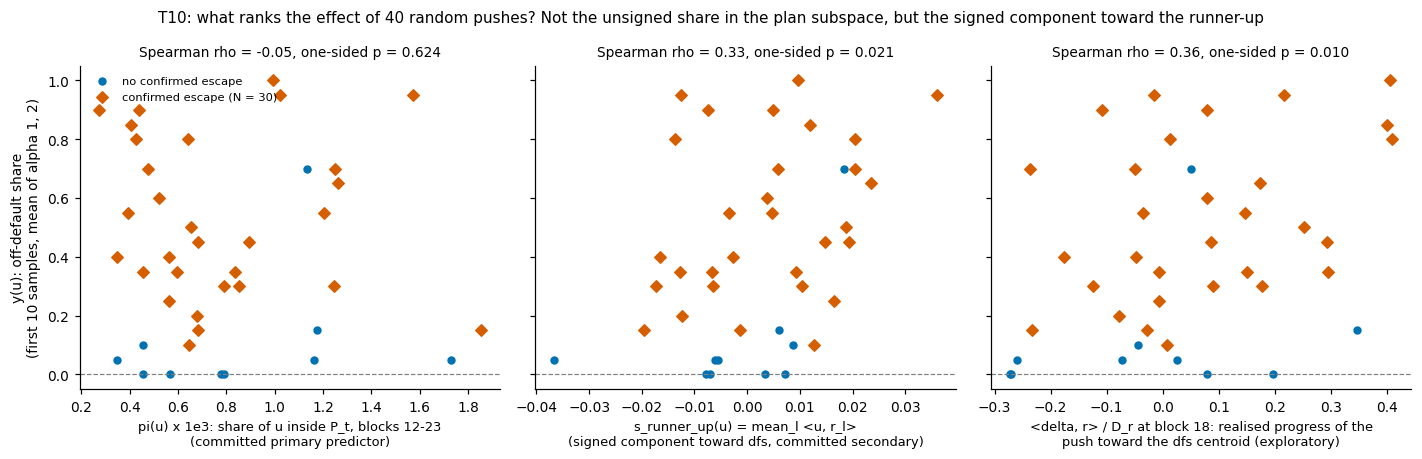

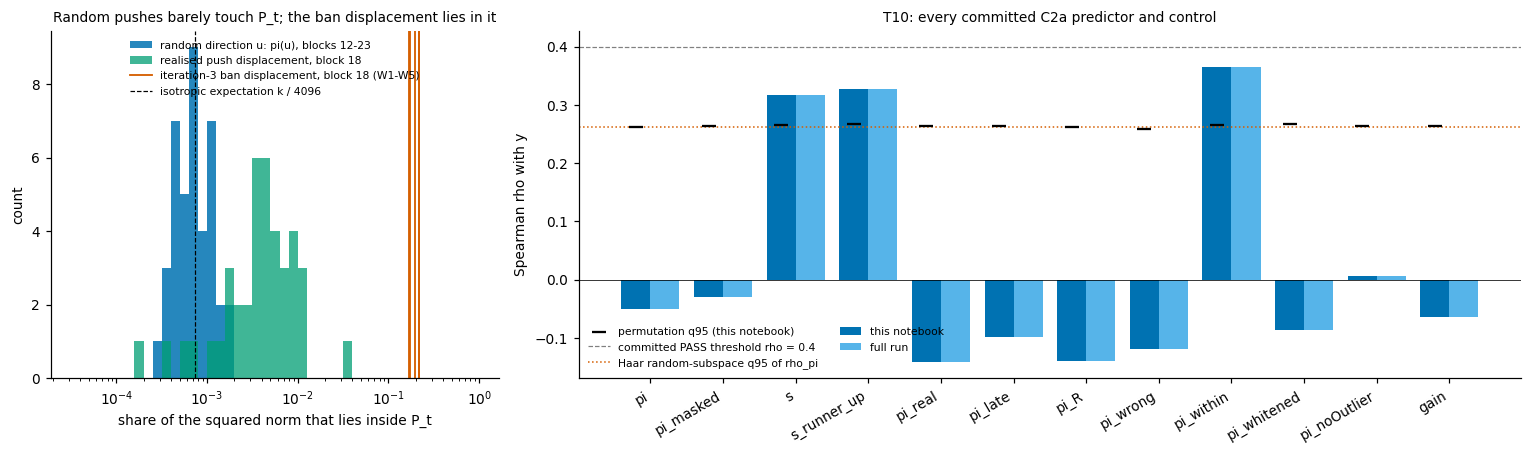

In [20]:
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})   # figures.py style
OI = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]   # Okabe-Ito

y = np.array(r["y"])
escv = np.array(r["escape"])
f18 = xt["features"][GEO_BLOCKS[0]]
panels = [(np.array([preds[str(s)]["pi"] for s in SEEDS_POP]) * 1e3, r["predictors"]["pi"],
           "pi(u) x 1e3: share of u inside P_t, blocks 12-23\n(committed primary predictor)"),
          (np.array([preds[str(s)]["s_runner_up"] for s in SEEDS_POP]), r["predictors"]["s_runner_up"],
           f"s_runner_up(u) = mean_l <u, r_l>\n(signed component toward {ru}, committed secondary)"),
          (np.array(f18["proj_r"]), {"rho": xt["profile"]["proj_r"][0], "p": xt["profile"]["proj_r_p"][0]},
           f"<delta, r> / D_r at block {GEO_BLOCKS[0]}: realised progress of the\npush toward the {ru} "
           "centroid (exploratory)")]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (x, st, lab) in zip(axs, panels):
    ax.scatter(x[escv == 0], y[escv == 0], s=20, c=OI[0], label="no confirmed escape")
    ax.scatter(x[escv == 1], y[escv == 1], s=28, c=OI[3], marker="D", label="confirmed escape (N = 30)")
    ax.axhline(r["twin"]["share"], color="grey", lw=0.8, ls="--")
    ax.set_title(f"Spearman rho = {st['rho']:.2f}, one-sided p = {st['p']:.3f}", fontsize=9)
    ax.set_xlabel(lab, fontsize=8.5)
axs[0].set_ylabel("y(u): off-default share\n(first 10 samples, mean of alpha 1, 2)")
axs[0].legend(fontsize=7.5, frameon=False, loc="upper left")
fig.suptitle(f"{TASK}: what ranks the effect of {len(SEEDS_POP)} random pushes? Not the unsigned share in the plan "
             "subspace, but the signed component toward the runner-up", fontsize=10)
fig.tight_layout()
plt.show()

names = ["pi", "pi_masked", "s", "s_runner_up", "pi_real", "pi_late", "pi_R", "pi_wrong", "pi_within",
         "pi_whitened", "pi_noOutlier", "gain"]   # the order of figures.py fig2
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.1]})
bins = np.logspace(-4.5, 0, 46)
ax0.hist([preds[str(s)]["pi"] for s in SEEDS_POP], bins=bins, color=OI[0], alpha=0.85,
         label="random direction u: pi(u), blocks 12-23")
ax0.hist(f18["pi"], bins=bins, color=OI[2], alpha=0.75, label=f"realised push displacement, block {GEO_BLOCKS[0]}")
for j, v in enumerate(pi_ban18.values()):
    ax0.axvline(v, color=OI[3], lw=1.2, label="iteration-3 ban displacement, block 18 (W1-W5)" if j == 0 else None)
ax0.axvline(k / 4096, color="k", ls="--", lw=0.8, label="isotropic expectation k / 4096")
ax0.set_xscale("log")
ax0.set_xlabel("share of the squared norm that lies inside P_t")
ax0.set_ylabel("count")
ax0.legend(fontsize=7, frameon=False, loc="upper center")
ax0.set_title("Random pushes barely touch P_t; the ban displacement lies in it", fontsize=9)
xx = np.arange(len(names))
ax1.bar(xx - 0.2, [r["predictors"][p]["rho"] for p in names], 0.4, color=OI[0], label="this notebook")
ax1.bar(xx + 0.2, [fr["predictors"][p]["rho"] for p in names], 0.4, color=OI[5], label="full run")
ax1.scatter(xx - 0.2, [r["predictors"][p]["null_q95"] for p in names], marker="_", color="k", s=90, zorder=3,
            label="permutation q95 (this notebook)")
ax1.axhline(RULE["rho_min"], color="grey", ls="--", lw=0.8, label="committed PASS threshold rho = 0.4")
ax1.axhline(r["haar_null"]["q95"], color=OI[3], ls=":", lw=1.0, label="Haar random-subspace q95 of rho_pi")
ax1.axhline(0, color="k", lw=0.5)
ax1.set_xticks(xx)
ax1.set_xticklabels(names, rotation=30, ha="right")
ax1.set_ylabel("Spearman rho with y")
ax1.legend(fontsize=7, frameon=False, ncol=2, loc="lower left")
ax1.set_title(f"{TASK}: every committed C2a predictor and control", fontsize=9)
fig.tight_layout()
plt.show()

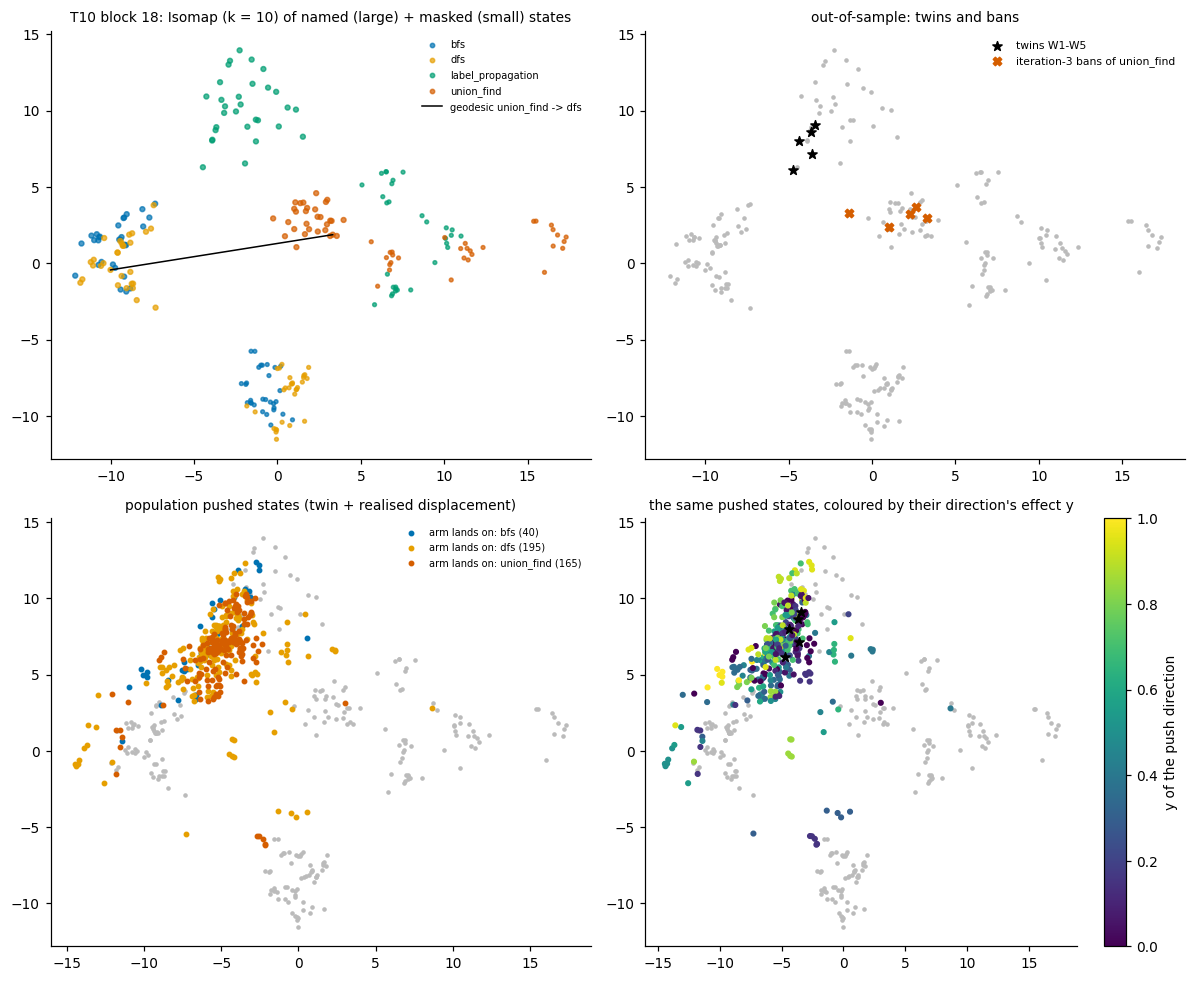

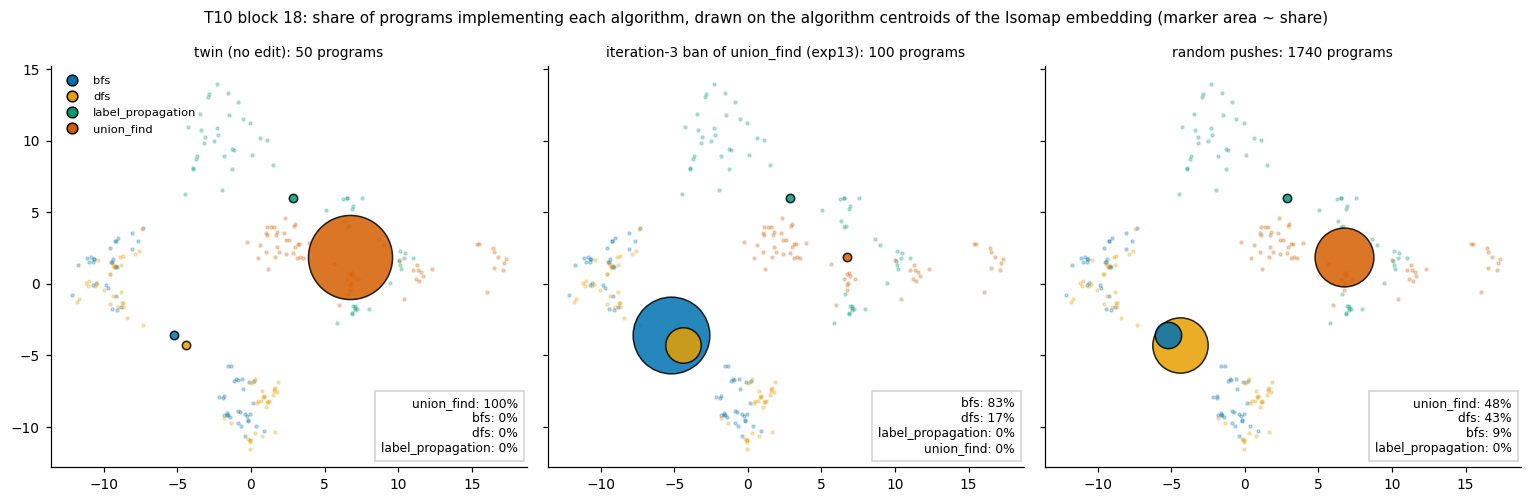

In [21]:
gT = geo["tasks"][TASK]
blk = str(GEO_BLOCKS[0])
e = gT[blk]["embedding_k10"]
P = np.array(e["points"])
labs = e["labels"]
modes_g = sorted(set(labs))
col = {m: OI[i % len(OI)] for i, m in enumerate(modes_g)}
o = e["oos"]
# --- fig6 of analysis/figures.py (panels 1-3 as there; panel 4 colours the pushed states by their direction's y,
#     because the C2c targeted arms that fig6 draws there are not in this slice)
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
ax = axs[0, 0]
for m in modes_g:
    ii = [i for i, l in enumerate(labs) if l == m]
    kk = [e["kinds"][i] for i in ii]
    ax.scatter(P[ii, 0], P[ii, 1], s=[10 if k_ == "named" else 6 for k_ in kk], color=col[m], label=m,
               marker="o", alpha=0.7)
gp = np.array(e["geodesic_path"])
ax.plot(gp[:, 0], gp[:, 1], "-", color="k", lw=1.0, label=f"geodesic {d} -> {ru}")
ax.set_title(f"{TASK} block {blk}: Isomap (k = 10) of named (large) + masked (small) states", fontsize=9)
ax.legend(fontsize=6.5, frameon=False)
ax = axs[0, 1]
ax.scatter(P[:, 0], P[:, 1], s=4, color="#BBBBBB")
T_ = np.array(o["twin"])
ax.scatter(T_[:, 0], T_[:, 1], s=40, marker="*", color=OI[7], label="twins W1-W5")
Bn = np.array(o["ban"])
ax.scatter(Bn[:, 0], Bn[:, 1], s=30, marker="X", color=OI[3], label=f"iteration-3 bans of {d}")
ax.legend(fontsize=7, frameon=False)
ax.set_title("out-of-sample: twins and bans", fontsize=9)
ax = axs[1, 0]
ax.scatter(P[:, 0], P[:, 1], s=4, color="#BBBBBB")
Qp = np.array(o["population"]["points"])
ll = o["population"]["landing"]
for m in sorted(set(ll)):
    ii = [i for i, l in enumerate(ll) if l == m]
    ax.scatter(Qp[ii, 0], Qp[ii, 1], s=8, color=col.get(m, "#999999"), label=f"arm lands on: {m} ({len(ii)})")
ax.legend(fontsize=6.5, frameon=False)
ax.set_title("population pushed states (twin + realised displacement)", fontsize=9)
ax = axs[1, 1]
ax.scatter(P[:, 0], P[:, 1], s=4, color="#BBBBBB")
ymap = dict(zip(SEEDS_POP, r["y"]))
yy = np.array([ymap.get(int(kk.split("|")[1]), np.nan) for kk in pop_keys])
okp = np.isfinite(yy)
sc = ax.scatter(Qp[okp, 0], Qp[okp, 1], c=yy[okp], cmap="viridis", vmin=0, vmax=1, s=9)
fig.colorbar(sc, ax=ax, label="y of the push direction")
ax.scatter(T_[:, 0], T_[:, 1], s=40, marker="*", color=OI[7])
ax.set_title("the same pushed states, coloured by their direction's effect y", fontsize=9)
fig.tight_layout()
plt.show()

# --- where the implemented algorithm sits on the plan-state manifold: share of programs per algorithm, drawn on the
#     algorithm centroids of the Isomap embedding, under the twin, the iteration-3 ban and the random pushes
ic = gT["implemented_counts"]
sources = [("twin", f"twin (no edit): {sum(ic['twin'].values())} programs"),
           ("iter3_ban", f"iteration-3 ban of {d} (exp13): {sum(ic['iter3_ban'].values())} programs"),
           ("push_population", f"random pushes: {sum(ic['push_population'].values())} programs")]
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, (src, ttl) in zip(axs, sources):
    cnt = ic.get(src, {})
    tot = sum(cnt.values())
    order = sorted(modes_g, key=lambda m_: -cnt.get(m_, 0))   # large markers first, so small ones stay visible
    for m in modes_g:
        ii = [i for i, l in enumerate(labs) if l == m]
        ax.scatter(P[ii, 0], P[ii, 1], s=4, color=col[m], alpha=0.25)
    for z_, m in enumerate(order):
        c = np.array(e["centroids"][m])
        sh_ = cnt.get(m, 0) / tot if tot else 0.0
        ax.scatter([c[0]], [c[1]], s=30 + 3000 * sh_, facecolor=col[m], edgecolor="k", alpha=0.85, zorder=3 + z_)
    ax.text(0.98, 0.03, "\n".join(f"{m}: {100 * cnt.get(m, 0) / max(tot, 1):.0f}%" for m in order),
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8,
            bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "#CCCCCC"})
    ax.set_title(ttl, fontsize=9)
axs[0].legend(handles=[matplotlib.lines.Line2D([0], [0], marker="o", ls="", markerfacecolor=col[m],
                                               markeredgecolor="k", markersize=7, label=m) for m in modes_g],
              fontsize=7.5, frameon=False, loc="upper left")
fig.suptitle(f"{TASK} block {blk}: share of programs implementing each algorithm, drawn on the algorithm centroids of "
             "the Isomap embedding (marker area ~ share)", fontsize=10)
fig.tight_layout()
plt.show()

## Reading the results

**On T10 the committed hypothesis fails exactly as in the full run.**

- **The plan subspace is real.** Two random halves of the forced paraphrases span almost the same 3-dimensional subspace: principal cosine 0.90, against 0.02 for random subspaces. Named and masked difference vectors agree only moderately (cosine 0.54–0.66), so `P_t` carries a lexical component. The iteration-3 ban's own displacement puts about 20% of its squared norm in `P_t` at block 18, about 270 times what an isotropic direction gets (k/4096 = 0.07%).
- **Random pushes act without it.** A random direction has π ≈ k/4096, and π does not rank the effect: ρ(π, y) = −0.05 (p = 0.62), inside the Haar random-subspace null. Yet 36 of 40 directions move the algorithm, and *which* ones do is reproducible across template halves (ρ = 0.90). The prediction target is stable; π just does not predict it.
- **What tracks the effect is the sign.** Three signed quantities correlate with y, while the unsigned share of the same displacement does not (ρ = −0.02):
  - the component of the push along the runner-up axis (`s_runner_up`, ρ = 0.33);
  - the realised progress toward the DFS centroid at block 18 (`proj_r`, ρ = 0.36);
  - the realised alignment with the mean non-default axis (`proj_a`, ρ = 0.52).

  A push helps when it happens to point toward the runner-up: a directional effect that the committed unsigned predictor cannot see. The committed within-class control `π_within` also reaches ρ = 0.37, so these unadjusted, exploratory correlations do not single out `P_t` either.
- **Geometry.** At block 18 the forced-prompt states form tight clusters, one per algorithm and prompt kind: the named and the masked prompts of an algorithm sit in separate clusters, and BFS and DFS overlap (figure C, top left). The pushed states stay near the twins, and pushes that changed the algorithm and pushes that did not are intermixed in the embedding (figure C, bottom).
- **Where the probability mass goes.** The twin writes union-find 100% of the time. Banning union-find moves the mass mostly to BFS (83%). Random pushes move it mostly to DFS (43%, with 48% still union-find). Neither moves it to label propagation, the algorithm whose centroid is nearest to union-find at block 18.

**Full run, all six movable tasks (not recomputed here).**

- **C2a:** DISCONFIRMED; pooled within-task ρ = 0.03 [−0.03, 0.09].
- **Decomposition:** removing the `P_t` component of 20 confirmed escaping pushes leaves their effect intact (median R = 1.00), so `P_t` is not needed.
- **C2c:** T10 is the one task where a targeted push along the runner-up axis works. At half the distance to the DFS centroid it gives 48% correct DFS, vs 0% for a random push of the same magnitude (McNemar p = 1.2e-7).
- **Novelty:** random pushes recombine catalogue algorithms. They produced 0 novel algorithms among 10,651 correct programs.